# 📐 Chapitre 1.1 — L'algèbre pour le Deep Learning

**Scalaires · Vecteurs · Matrices · Tenseurs · Broadcasting**

> *Partie I — Fondations Mathématiques · Chapitre 01 — Tenseurs et Calcul Différentiel · Sous-chapitre 1.1*

---

## 🎯 Objectifs de ce notebook

À la fin de ce notebook, tu sauras :

1. Expliquer ce qu'est un **scalaire**, un **vecteur**, une **matrice** et un **tenseur**, et lire sans effort leur **shape**.
2. Manipuler ces objets avec **NumPy** (création, indexation, slicing, reshape, axes, réductions).
3. Comprendre la **géométrie** derrière : addition, produit scalaire, normes, angles, projections, transformations linéaires.
4. Maîtriser le **produit matriciel** et son interprétation (la brique de base de *toute* couche de réseau de neurones).
5. Comprendre et **prédire le broadcasting** sans jamais tâtonner.
6. Lire et écrire de l'**`einsum`** (indispensable pour l'attention des Transformers).
7. Écrire à la main le **forward pass d'une couche dense** puis d'un petit MLP, et comprendre pourquoi les non-linéarités sont indispensables.
8. Connaître les **pièges numériques** (flottants, overflow) qui reviendront dans tous les chapitres suivants.

## 🧭 Prérequis

Uniquement Python de base (variables, boucles, fonctions, listes). **Aucune connaissance préalable en algèbre linéaire n'est supposée** : on repart vraiment de zéro.

## 🗺️ Comment utiliser ce notebook

- Exécute les cellules **dans l'ordre** (`Shift + Entrée`). Les cellules suivantes réutilisent les variables des précédentes.
- **Modifie les valeurs**, casse les choses, relance : c'est comme ça qu'on comprend.
- Les pictogrammes t'aident à repérer le type d'information :

| Pictogramme | Signification |
|---|---|
| 🧠 | Intuition : comprendre *pourquoi* |
| 🔬 | Formalisme mathématique |
| 💻 | Code NumPy |
| ⚠️ | Piège classique (source de bugs réels !) |
| 🎯 | Lien direct avec le Deep Learning |
| ✏️ | Exercice (avec solution repliée) |

## 📑 Plan

0. Mise en place
1. Pourquoi l'algèbre linéaire ? (le teaser)
2. Les **scalaires** (et la précision des flottants)
3. Les **vecteurs** (opérations, géométrie, normes, produit scalaire, similarité cosinus)
4. Les **matrices** (indexation, transposée, transformations linéaires, produit matriciel, inverse)
5. Les **tenseurs** (shapes, axes, réductions, reshape, vues vs copies)
6. Le **broadcasting**
7. **`einsum`** : une notation pour les gouverner toutes
8. Application : la **couche dense** et le **MLP**, forward pass à la main
9. **Vectorisation** et **stabilité numérique**
10. Exercices
11. Récapitulatif, questions d'entretien et suite

---
# 0. Mise en place

On commence par importer les bibliothèques et configurer l'affichage.

- **NumPy** : la bibliothèque de calcul sur tableaux n-dimensionnels. C'est le « Excel sous stéroïdes » de Python scientifique, et PyTorch en reprend presque toute l'API.
- **Matplotlib** : pour tracer des graphiques et *voir* ce que font les maths.

💻 On fixe aussi un **générateur aléatoire avec une graine (seed)** : ainsi, les résultats « aléatoires » sont **reproductibles**. En ML, la reproductibilité est une habitude vitale.

In [1]:
import sys
import time

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Générateur aléatoire moderne, reproductible grâce à la graine (seed)
rng = np.random.default_rng(42)

# Style des graphiques
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

print(f"Python     : {sys.version.split()[0]}")
print(f"NumPy      : {np.__version__}")
print(f"Matplotlib : {mpl.__version__}")

Python     : 3.13.3
NumPy      : 2.2.6
Matplotlib : 3.10.1


---
# 1. Pourquoi l'algèbre linéaire ? Le teaser 🎯

🧠 **Une idée simple mais fondamentale** : un ordinateur ne comprend que des **nombres**. Pour qu'un réseau de neurones traite une image, un texte, un son ou une ligne de tableur, il faut tout transformer en **tableaux de nombres**.

- Une **image** devient un tableau de pixels (hauteur × largeur × canaux de couleur).
- Un **mot** devient une liste de nombres (un *embedding*).
- Un **client** dans une base de données devient une liste de caractéristiques (âge, revenu, ...).

Et ce que fait un réseau de neurones, au fond, c'est **enchaîner des opérations d'algèbre linéaire** (multiplications de matrices) **entrecoupées de petites non-linéarités**. Voici le « cœur » d'une couche de réseau de neurones, en trois lignes :

In [2]:
X = rng.normal(size=(4, 3))      # 4 exemples, chacun décrit par 3 caractéristiques
W = rng.normal(size=(3, 2))      # des « poids » : 3 entrées -> 2 sorties
b = np.zeros(2)                  # un « biais »

Y = np.maximum(0, X @ W + b)     # la couche : multiplication matricielle + biais + ReLU

print("X :", X.shape, "-> Y :", Y.shape)
print(Y)

X : (4, 3) -> Y : (4, 2)
[[0.         0.51754556]
 [0.         3.98539041]
 [0.         0.43196218]
 [0.64161107 0.        ]]


Pour l'instant, cette cellule est peut-être mystérieuse : `@`, `shape`, `(4, 3)`, `+ b` avec des tailles différentes (c'est du **broadcasting** !), `np.maximum(0, ...)`.

**À la fin de ce notebook, tu comprendras chaque symbole de ces trois lignes, et tu sauras les réécrire de zéro.** C'est exactement l'objectif de ce repo : *comprendre ce qui se passe sous le capot*.

---
# 2. Les scalaires

## 🧠 Définition

Un **scalaire** est un **nombre unique**. Rien de plus : `3`, `-0.5`, `3.14159`.

En Deep Learning, un scalaire peut être :
- une **perte** (*loss*) : *« mon modèle se trompe de 0.37 »* ;
- un **taux d'apprentissage** (*learning rate*) : `0.001` ;
- un **poids** individuel du réseau, une probabilité, une température, etc.

🔬 **Notation** : on note les scalaires par des lettres minuscules italiques, par exemple $a \in \mathbb{R}$. Le symbole $\in$ se lit « appartient à » et $\mathbb{R}$ désigne l'ensemble des nombres réels.

## 💻 Scalaires en Python et NumPy

Python a ses propres nombres (`int`, `float`). NumPy possède des types plus précis (`np.float32`, `np.float64`, ...) et un « tableau à 0 dimension » qui représente un scalaire.

In [3]:
a = 3.5                  # un float Python
b = np.float32(3.5)      # un scalaire NumPy en 32 bits
c = np.array(3.5)        # un tableau NumPy à 0 dimension

print("type de a :", type(a))
print("type de b :", type(b))
print("type de c :", type(c))
print()
print("c.ndim  =", c.ndim,  "  (nombre de dimensions : 0 pour un scalaire)")
print("c.shape =", c.shape, "  (une shape vide : pas d'axes)")
print("c.size  =", c.size,  "  (nombre total d'éléments)")
print("c.dtype =", c.dtype, "  (type de données)")

type de a : <class 'float'>
type de b : <class 'numpy.float32'>
type de c : <class 'numpy.ndarray'>

c.ndim  = 0   (nombre de dimensions : 0 pour un scalaire)
c.shape = ()   (une shape vide : pas d'axes)
c.size  = 1   (nombre total d'éléments)
c.dtype = float64   (type de données)


🧠 Retiens ce vocabulaire dès maintenant, il sera partout :

| Terme | Signification |
|---|---|
| **`ndim`** | Nombre de dimensions (d'*axes*) du tableau |
| **`shape`** | Tuple donnant la taille le long de chaque axe |
| **`size`** | Nombre total d'éléments (produit des tailles de la `shape`) |
| **`dtype`** | Type des éléments (`float32`, `float64`, `int64`, ...) |

## ⚠️ Les nombres flottants ne sont PAS les nombres réels

Un ordinateur stocke les nombres décimaux sous forme de **flottants** (*floating point*), avec un nombre **fini de bits**. Il ne peut donc représenter qu'un **ensemble fini** de valeurs : les autres sont **arrondies**. Ça a des conséquences très concrètes en Deep Learning.

In [4]:
print("0.1 + 0.2        =", 0.1 + 0.2)
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3, " <- surprenant, mais normal !")
print("np.isclose(0.1 + 0.2, 0.3) ?", np.isclose(0.1 + 0.2, 0.3), " <- la bonne façon de comparer")
print()
print("0.1 en 64 bits (20 décimales) :", f"{np.float64(0.1):.20f}")
print("0.1 en 32 bits (20 décimales) :", f"{np.float32(0.1):.20f}")

0.1 + 0.2        = 0.30000000000000004
0.1 + 0.2 == 0.3 ? False  <- surprenant, mais normal !
np.isclose(0.1 + 0.2, 0.3) ? True  <- la bonne façon de comparer

0.1 en 64 bits (20 décimales) : 0.10000000000000000555
0.1 en 32 bits (20 décimales) : 0.10000000149011611938


🧠 **Pourquoi `0.1 + 0.2 != 0.3` ?** Parce que `0.1` n'est pas représentable exactement en binaire (comme $1/3 = 0.333...$ n'est pas représentable exactement en décimal). L'ordinateur stocke l'approximation la plus proche, et les erreurs d'arrondi s'accumulent.

👉 **Règle d'or** : on ne compare **jamais** deux flottants avec `==`. On utilise `np.isclose` (pour des scalaires) ou `np.allclose` (pour des tableaux).

### Les types de flottants usuels en Deep Learning

| Type | Bits | Précision relative (`eps`) | Usage |
|---|---|---|---|
| `float64` | 64 | ~2.2e-16 | Calcul scientifique (NumPy par défaut) |
| `float32` | 32 | ~1.2e-07 | **Standard** de l'entraînement (PyTorch par défaut) |
| `float16` | 16 | ~9.8e-04 | Entraînement en précision mixte, inférence |
| `bfloat16` | 16 | ~7.8e-03 | Entraînement de LLM (plage de valeurs large) |

(`bfloat16` n'existe pas nativement dans NumPy, mais on le rencontrera avec PyTorch.)

`eps` (« epsilon machine ») est le plus petit nombre tel que `1 + eps != 1` : c'est la **précision relative** du type.

In [5]:
print(f"{'type':>8} | {'bits':>4} | {'eps':>9} | {'plus petit > 0':>14} | {'plus grand':>10}")
print("-" * 58)
for dt in (np.float16, np.float32, np.float64):
    info = np.finfo(dt)
    print(f"{dt.__name__:>8} | {info.bits:>4} | {info.eps:>9.2e} | {info.tiny:>14.2e} | {info.max:>10.2e}")

    type | bits |       eps | plus petit > 0 | plus grand
----------------------------------------------------------
 float16 |   16 |  9.77e-04 |       6.10e-05 |   6.55e+04
 float32 |   32 |  1.19e-07 |       1.18e-38 |   3.40e+38
 float64 |   64 |  2.22e-16 |      2.23e-308 |  1.80e+308


### Trois phénomènes à connaître

1. **L'absorption** : ajouter un tout petit nombre à un très grand nombre peut ne *rien changer*.
2. **L'overflow** (dépassement) : un nombre trop grand devient `inf` (infini).
3. **L'underflow** : un nombre trop proche de zéro devient `0`.

In [6]:
# 1. Absorption
grand = np.float32(1e8)
print("1e8 + 1 == 1e8 en float32 ?", (grand + np.float32(1)) == grand, " <- le +1 a été 'absorbé'")

# 2. Overflow : float16 ne dépasse pas ~65504
with np.errstate(over="ignore"):
    print("70000 en float16 ->", np.array(70000.0).astype(np.float16))

# 3. Underflow : float32 ne descend pas sous ~1e-45
with np.errstate(under="ignore"):
    print("1e-50 en float32 ->", np.array(1e-50).astype(np.float32))

1e8 + 1 == 1e8 en float32 ? True  <- le +1 a été 'absorbé'
70000 en float16 -> inf
1e-50 en float32 -> 0.0


Pour *voir* ce phénomène, traçons l'**écart entre un nombre et le flottant suivant** (`np.spacing`). Plus un nombre est grand, plus les flottants voisins sont **espacés** : la précision *absolue* diminue, alors que la précision *relative* reste constante.

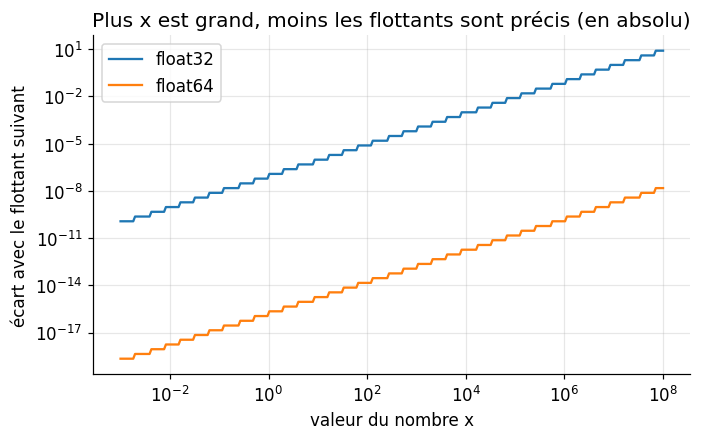

In [7]:
x = np.logspace(-3, 8, 300)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(x, np.spacing(x.astype(np.float32)), label="float32")
ax.loglog(x, np.spacing(x.astype(np.float64)), label="float64")
ax.set_xlabel("valeur du nombre x")
ax.set_ylabel("écart avec le flottant suivant")
ax.set_title("Plus x est grand, moins les flottants sont précis (en absolu)")
ax.legend()
plt.show()

## 🎯 Pourquoi c'est important en Deep Learning ?

- Les **LLM** s'entraînent en `bfloat16` ou `float16` pour économiser mémoire et temps de calcul : il faut comprendre ce qu'on perd.
- Les calculs comme `exp(x)` **débordent** très vite : c'est pour ça que la fonction *softmax* s'implémente avec une astuce de stabilité (on la verra en section 9).
- Des **gradients minuscules** peuvent s'annuler (*underflow*) : c'est un des problèmes historiques des réseaux profonds.

✅ **À retenir** : un scalaire = 1 nombre, `shape = ()`, `ndim = 0`. Et les flottants sont des **approximations** : on compare avec `isclose`, on se méfie de `exp` et des très grands/petits nombres.

---
# 3. Les vecteurs

## 🧠 Définition et intuition

Un **vecteur** est une **liste ordonnée de nombres**. Il a deux interprétations complémentaires, qu'il faut toujours garder en tête :

1. **Interprétation « données »** : un vecteur est une liste de caractéristiques. Par exemple, une maison = `[surface, nb_chambres, âge]` = `[120, 3, 15]`.
2. **Interprétation « géométrique »** : un vecteur est un **point** (ou une **flèche** depuis l'origine) dans un espace à $n$ dimensions. Le vecteur `[3, 1]` est la flèche qui va de l'origine au point d'abscisse 3 et d'ordonnée 1.

🔬 **Notation** : on note un vecteur $\mathbf{v} \in \mathbb{R}^n$ (lettre minuscule en gras), avec $n$ sa **dimension** :

$$\mathbf{v} = \begin{pmatrix} v_1 \\ v_2 \\ \vdots \\ v_n \end{pmatrix}$$

## 🎯 Où trouve-t-on des vecteurs en Deep Learning ?

- Les **entrées** d'un modèle (une ligne de données).
- Les **embeddings** : un mot, une image ou un utilisateur est représenté par un vecteur de quelques centaines à milliers de dimensions. Un LLM manipule des vecteurs de dimension 4096 ou plus !
- Les **biais** d'une couche, les **gradients** (chapitres suivants), les **logits** de sortie.

In [ ]:
v = np.array([2.0, 1.0, -1.0])

print("v        =", v)
print("v.shape  =", v.shape, " <- un tuple à UN élément : (3,)")
print("v.ndim   =", v.ndim)
print("v.size   =", v.size)
print("v[0]     =", v[0], "  (l'indexation commence à 0 !)")
print("v[-1]    =", v[-1], " (le dernier élément)")
print("v[0:2]   =", v[0:2], "  (slicing : éléments 0 et 1, le 2 est exclu)")

## ⚠️ Piège n°1 : la shape `(n,)` n'est ni une ligne ni une colonne

En mathématiques, on distingue un vecteur **colonne** (n × 1) d'un vecteur **ligne** (1 × n). En NumPy, un tableau de shape **`(n,)`** est un vecteur « à plat », **sans orientation**. Les shapes `(n, 1)` (colonne) et `(1, n)` (ligne) sont des **matrices** à part entière, et elles ne se comportent pas pareil !

C'est une source classique de bugs silencieux. Regarde :

In [ ]:
v_plat = np.array([1, 2, 3])        # shape (3,)
v_col  = v_plat.reshape(-1, 1)      # shape (3, 1)  -> colonne
v_lig  = v_plat.reshape(1, -1)      # shape (1, 3)  -> ligne

print("v_plat :", v_plat.shape)
print("v_col  :", v_col.shape)
print("v_lig  :", v_lig.shape)
print()
print("v_plat + v_plat ->", (v_plat + v_plat).shape, " (OK, on attend un vecteur)")
print("v_plat + v_col  ->", (v_plat + v_col).shape,  " (surprise : une MATRICE 3x3 !)")
print()
print(v_plat + v_col)

🧠 Que s'est-il passé ? C'est du **broadcasting** (section 6) : NumPy a « étiré » les deux tableaux pour les rendre compatibles, et a produit une matrice 3×3 contenant toutes les sommes $v_i + v_j$. Ce n'est *presque jamais* ce qu'on voulait en additionnant deux vecteurs.

👉 **Règle pratique** : en cas de doute, **affiche toujours les `shape`**. Le réflexe `print(x.shape)` te sauvera des heures de débogage. (Le `-1` dans `reshape(-1, 1)` signifie « déduis cette taille automatiquement ».)

## 3.1 Opérations de base : addition et multiplication par un scalaire

🔬 Pour deux vecteurs $\mathbf{u}, \mathbf{w} \in \mathbb{R}^n$ et un scalaire $\alpha \in \mathbb{R}$ :

- **Addition** (composante par composante) : $(\mathbf{u} + \mathbf{w})_i = u_i + w_i$
- **Multiplication par un scalaire** : $(\alpha \mathbf{u})_i = \alpha \cdot u_i$

🧠 **Géométriquement** :
- Additionner deux vecteurs = enchaîner les flèches (règle du **parallélogramme**).
- Multiplier par un scalaire = **étirer** ($|\alpha| > 1$), **rétrécir** ($|\alpha| < 1$) ou **retourner** ($\alpha < 0$) la flèche.

Pour visualiser, on définit d'abord une petite fonction utilitaire de tracé de flèches.

In [ ]:
def tracer_vecteurs(ax, vecteurs, labels, couleurs, origines=None, xlim=(-1, 5), ylim=(-1, 5), style="-"):
    # Trace des vecteurs 2D sous forme de flèches sur l'axe `ax`.
    if origines is None:
        origines = [(0, 0)] * len(vecteurs)
    for v, label, couleur, o in zip(vecteurs, labels, couleurs, origines):
        ax.quiver(o[0], o[1], v[0], v[1], angles="xy", scale_units="xy", scale=1,
                  color=couleur, width=0.007, linestyle=style)
        ax.annotate(label, (o[0] + v[0], o[1] + v[1]), textcoords="offset points",
                    xytext=(7, 7), color=couleur, fontsize=13, fontweight="bold")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(0, color="black", lw=0.8)

In [ ]:
u = np.array([3.0, 1.0])
w = np.array([1.0, 2.0])

print("u + w =", u + w)
print("2 * u =", 2 * u)
print("-u    =", -u)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gauche : addition = règle du parallélogramme
tracer_vecteurs(axes[0],
                [u, w, w, u, u + w],
                ["u", "w", "", "", "u + w"],
                ["tab:blue", "tab:orange", "tab:orange", "tab:blue", "tab:green"],
                origines=[(0, 0), (0, 0), tuple(u), tuple(w), (0, 0)],
                xlim=(-1, 5.5), ylim=(-1, 4.5))
axes[0].set_title("Addition : règle du parallélogramme")

# Droite : multiplication par un scalaire
tracer_vecteurs(axes[1],
                [u, 2 * u, 0.5 * u, -u],
                ["u", "2u", "0.5u", "-u"],
                ["tab:blue", "tab:red", "tab:purple", "tab:gray"],
                xlim=(-4, 7), ylim=(-2, 3))
axes[1].set_title("Multiplication par un scalaire")

plt.tight_layout()
plt.show()

## 3.2 Combinaisons linéaires et « span »

Une **combinaison linéaire** de vecteurs $\mathbf{u}$ et $\mathbf{w}$ est toute expression de la forme

$$a\,\mathbf{u} + b\,\mathbf{w}, \qquad a, b \in \mathbb{R}$$

🧠 C'est LA notion centrale de l'algèbre linéaire, et elle revient partout : **une couche de réseau de neurones calcule des combinaisons linéaires de ses entrées**.

L'ensemble de **toutes** les combinaisons linéaires possibles s'appelle le **span** (l'« engendré ») des vecteurs. Question clé : *quelle région de l'espace peut-on atteindre ?*

- Deux vecteurs 2D **non alignés** engendrent **tout le plan**.
- Deux vecteurs **alignés** (colinéaires) n'engendrent qu'**une droite** : le deuxième est redondant.

On dit alors que les vecteurs sont **linéairement dépendants** (l'un est combinaison des autres) ou **indépendants** dans le cas contraire. Cette notion, ce sera la clé pour comprendre le **rang** d'une matrice.

In [ ]:
u = np.array([3.0, 1.0])
w = np.array([1.0, 2.0])
w_colineaire = 2 * u            # aligné avec u -> redondant

coef = np.linspace(-2, 2, 15)
A, B = np.meshgrid(coef, coef)  # toutes les paires (a, b)

# A.reshape(-1, 1) est de shape (225, 1) ; u est de shape (2,) -> broadcast -> (225, 2)
pts_plan   = A.reshape(-1, 1) * u + B.reshape(-1, 1) * w
pts_droite = A.reshape(-1, 1) * u + B.reshape(-1, 1) * w_colineaire

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pts, v2, titre in [
    (axes[0], pts_plan, w, "u et w non alignés : on atteint tout le plan"),
    (axes[1], pts_droite, w_colineaire, "u et 2u alignés : on n'atteint qu'une droite"),
]:
    ax.scatter(pts[:, 0], pts[:, 1], s=14, alpha=0.5, color="tab:green")
    tracer_vecteurs(ax, [u, v2], ["u", "w" if v2 is w else "2u"], ["tab:blue", "tab:orange"],
                    xlim=(-9, 9), ylim=(-9, 9))
    ax.set_title(titre)
plt.tight_layout()
plt.show()

## 3.3 Le produit scalaire (*dot product*)

C'est **l'opération la plus importante** de tout ce notebook (et sans doute de tout le Deep Learning).

🔬 **Définition** : pour $\mathbf{u}, \mathbf{w} \in \mathbb{R}^n$,

$$\mathbf{u} \cdot \mathbf{w} = \sum_{i=1}^{n} u_i w_i = u_1 w_1 + u_2 w_2 + \dots + u_n w_n$$

On multiplie composante par composante, puis on **additionne** : le résultat est un **scalaire**.

🔬 **Formule géométrique** (équivalente) :

$$\mathbf{u} \cdot \mathbf{w} = \|\mathbf{u}\| \, \|\mathbf{w}\| \cos\theta$$

où $\theta$ est l'angle entre les deux vecteurs et $\|\cdot\|$ la longueur (norme, voir plus bas).

🧠 **Intuition : le produit scalaire mesure l'alignement de deux vecteurs.**

| Signe du produit scalaire | Angle $\theta$ | Interprétation |
|---|---|---|
| $> 0$ | $< 90°$ | Les vecteurs pointent dans des directions *similaires* |
| $= 0$ | $= 90°$ | Les vecteurs sont **orthogonaux** (aucun lien) |
| $< 0$ | $> 90°$ | Les vecteurs pointent dans des directions *opposées* |

🎯 **Un neurone, c'est un produit scalaire !** Un neurone calcule $\mathbf{w} \cdot \mathbf{x} + b$ : il mesure à quel point l'entrée $\mathbf{x}$ « ressemble » à son motif préféré $\mathbf{w}$. Et dans un Transformer, l'**attention** compare des vecteurs *requête* et *clé* avec... un produit scalaire.

In [ ]:
u = np.array([4.0, 1.5])
w = np.array([2.0, 3.0])

# Trois façons de calculer le même produit scalaire
dot_manuel = sum(ui * wi for ui, wi in zip(u, w))     # la définition, à la main
dot_np     = np.dot(u, w)                              # fonction NumPy
dot_arobase = u @ w                                    # opérateur @ (le plus idiomatique)

print("à la main :", dot_manuel)
print("np.dot    :", dot_np)
print("u @ w     :", dot_arobase)

# Vérification de la formule géométrique
norme_u, norme_w = np.linalg.norm(u), np.linalg.norm(w)
cos_theta = (u @ w) / (norme_u * norme_w)
theta_deg = np.degrees(np.arccos(cos_theta))
print(f"\n||u|| = {norme_u:.3f}, ||w|| = {norme_w:.3f}")
print(f"cos(theta) = {cos_theta:.3f}  ->  theta = {theta_deg:.1f} degrés")

### Projection orthogonale

Le produit scalaire permet de calculer la **projection** de $\mathbf{u}$ sur $\mathbf{w}$ : « l'ombre » de $\mathbf{u}$ sur la droite portée par $\mathbf{w}$.

$$\text{proj}_{\mathbf{w}}(\mathbf{u}) = \frac{\mathbf{u} \cdot \mathbf{w}}{\mathbf{w} \cdot \mathbf{w}} \, \mathbf{w}$$

Le reste, $\mathbf{u} - \text{proj}_{\mathbf{w}}(\mathbf{u})$, est **orthogonal** à $\mathbf{w}$. Cette idée de décomposer un vecteur en « partie alignée » + « partie orthogonale » est à la base de la régression linéaire (moindres carrés) et de la PCA.

In [ ]:
proj = (u @ w) / (w @ w) * w
reste = u - proj

print("projection de u sur w :", proj)
print("reste u - proj        :", reste)
print("reste · w             :", np.round(reste @ w, 10), " <- ≈ 0 : le reste est orthogonal à w")

fig, ax = plt.subplots(figsize=(6.5, 5))
tracer_vecteurs(ax, [u, w, proj], ["u", "w", "proj"],
                ["tab:blue", "tab:orange", "tab:green"], xlim=(-1, 5), ylim=(-1, 4))
ax.plot([proj[0], u[0]], [proj[1], u[1]], "k--", lw=1.2, label="reste (orthogonal à w)")
ax.set_title("Projection orthogonale de u sur w")
ax.legend(loc="upper left")
plt.show()

### Le cosinus comme mesure d'alignement

Traçons $\cos\theta$ en fonction de l'angle pour bien visualiser le lien avec le signe du produit scalaire.

In [ ]:
theta = np.linspace(0, np.pi, 300)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.degrees(theta), np.cos(theta), lw=2.5, color="tab:blue")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(90, color="gray", ls="--")
ax.fill_between(np.degrees(theta), np.cos(theta), 0, where=np.cos(theta) > 0, alpha=0.2, color="green")
ax.fill_between(np.degrees(theta), np.cos(theta), 0, where=np.cos(theta) < 0, alpha=0.2, color="red")
ax.text(25, 0.25, "alignés\n(produit scalaire > 0)", color="darkgreen")
ax.text(110, -0.55, "opposés\n(produit scalaire < 0)", color="darkred")
ax.annotate("orthogonaux", (90, 0), xytext=(95, 0.35), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("angle entre les vecteurs (degrés)")
ax.set_ylabel("cos(angle)")
ax.set_title("Le cosinus mesure l'alignement entre deux directions")
plt.show()

## 3.4 Les normes : mesurer la « taille » d'un vecteur

Une **norme** associe à un vecteur un nombre positif qui mesure sa « longueur » ou sa « taille ». Plusieurs normes existent, chacune avec sa géométrie.

🔬 Pour $\mathbf{v} \in \mathbb{R}^n$ :

| Norme | Formule | Intuition |
|---|---|---|
| **L2** (euclidienne) | $\|\mathbf{v}\|_2 = \sqrt{\sum_i v_i^2}$ | La longueur « à vol d'oiseau » (théorème de Pythagore) |
| **L1** (Manhattan) | $\|\mathbf{v}\|_1 = \sum_i \lvert v_i \rvert$ | La distance « en ville », en suivant les rues |
| **L∞** (max) | $\|\mathbf{v}\|_\infty = \max_i \lvert v_i \rvert$ | La plus grande composante |

On a aussi $\|\mathbf{v}\|_2^2 = \mathbf{v} \cdot \mathbf{v}$ : **le carré de la norme L2 est le produit scalaire du vecteur avec lui-même**.

🎯 **Liens avec le Deep Learning** :
- **L2** : régularisation *weight decay* (on pénalise les gros poids), erreur quadratique moyenne (MSE), *gradient clipping* (on limite la norme du gradient).
- **L1** : régularisation qui favorise des poids **nuls** (parcimonie), erreur absolue moyenne (MAE).

In [ ]:
v = np.array([3.0, -4.0])

l1   = np.sum(np.abs(v))
l2   = np.sqrt(np.sum(v ** 2))
linf = np.max(np.abs(v))

print(f"L1   à la main : {l1}   | np.linalg.norm(v, 1)      : {np.linalg.norm(v, 1)}")
print(f"L2   à la main : {l2}   | np.linalg.norm(v)         : {np.linalg.norm(v)}")
print(f"L∞   à la main : {linf}   | np.linalg.norm(v, np.inf) : {np.linalg.norm(v, np.inf)}")
print()
print("Vérif : ||v||_2^2 == v · v ?", np.isclose(np.linalg.norm(v) ** 2, v @ v))

### À quoi ressemblent ces normes ? Les « boules unité »

L'ensemble des vecteurs de norme exactement 1 s'appelle la **sphère unité** de cette norme. En 2D, sa forme change complètement selon la norme choisie : **losange** pour L1, **cercle** pour L2, **carré** pour L∞.

🧠 C'est la raison géométrique pour laquelle la régularisation L1 produit des poids exactement nuls : les « coins » du losange sont sur les axes.

In [ ]:
theta = np.linspace(0, 2 * np.pi, 400)
directions = np.stack([np.cos(theta), np.sin(theta)], axis=1)    # (400, 2) : des directions variées

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (p, nom, couleur) in zip(axes, [(1, "L1 (losange)", "tab:red"),
                                         (2, "L2 (cercle)", "tab:blue"),
                                         (np.inf, "L∞ (carré)", "tab:green")]):
    normes = np.linalg.norm(directions, ord=p, axis=1, keepdims=True)   # (400, 1)
    boule = directions / normes                                          # on ramène chaque direction à la norme 1
    ax.plot(boule[:, 0], boule[:, 1], color=couleur, lw=2.5)
    ax.fill(boule[:, 0], boule[:, 1], color=couleur, alpha=0.12)
    ax.set_aspect("equal")
    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_title(f"Norme {nom}")
plt.tight_layout()
plt.show()

### Distance entre deux vecteurs et normalisation

- La **distance** entre $\mathbf{u}$ et $\mathbf{w}$ est la norme de leur différence : $d(\mathbf{u}, \mathbf{w}) = \|\mathbf{u} - \mathbf{w}\|$.
- **Normaliser** un vecteur, c'est le diviser par sa norme pour obtenir un vecteur de **longueur 1** (un « vecteur unitaire ») qui garde la même direction : $\hat{\mathbf{v}} = \mathbf{v} / \|\mathbf{v}\|$.

In [ ]:
u = np.array([1.0, 2.0, 3.0])
w = np.array([4.0, 0.0, 3.0])

distance = np.linalg.norm(u - w)
print("distance(u, w) =", round(distance, 4))

v = np.array([3.0, 4.0])
v_unitaire = v / np.linalg.norm(v)
print("v =", v, "-> normalisé :", v_unitaire, "| sa norme :", np.linalg.norm(v_unitaire))

## 3.5 La similarité cosinus

La **similarité cosinus** compare **uniquement les directions** de deux vecteurs, en ignorant leur longueur :

$$\text{cos\_sim}(\mathbf{u}, \mathbf{w}) = \frac{\mathbf{u} \cdot \mathbf{w}}{\|\mathbf{u}\| \, \|\mathbf{w}\|} = \cos\theta \in [-1, 1]$$

- $+1$ : même direction ; $0$ : orthogonaux ; $-1$ : directions opposées.

🎯 C'est **la** mesure standard pour comparer des **embeddings** : recherche sémantique, RAG (chapitre 12), recommandation... Deux phrases qui ont le même sens ont des embeddings dans des directions proches.

Faisons une petite expérience avec des « mini-embeddings » **inventés** à 3 dimensions *(royauté, genre masculin, fruit)*. Dans un vrai modèle, ces dimensions ne sont pas interprétables aussi simplement, mais l'idée est la même.

In [ ]:
def similarite_cosinus(u, v):
    return (u @ v) / (np.linalg.norm(u) * np.linalg.norm(v))

# dimensions : (royauté, masculin, fruit)
mots = {
    "roi":   np.array([0.9,  0.9, 0.0]),
    "reine": np.array([0.9, -0.9, 0.0]),
    "homme": np.array([0.1,  0.9, 0.0]),
    "femme": np.array([0.1, -0.9, 0.0]),
    "pomme": np.array([0.0,  0.0, 1.0]),
    "poire": np.array([0.0,  0.1, 0.95]),
}
noms = list(mots)
M = np.stack([mots[n] for n in noms])             # matrice (6, 3) : une ligne par mot

# Matrice des similarités : on normalise chaque ligne puis on fait tous les produits scalaires d'un coup
M_norm = M / np.linalg.norm(M, axis=1, keepdims=True)
S = M_norm @ M_norm.T                              # (6, 6)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(noms)), noms, rotation=45)
ax.set_yticks(range(len(noms)), noms)
ax.grid(False)
for i in range(len(noms)):
    for j in range(len(noms)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="similarité cosinus")
ax.set_title("Similarité cosinus entre mini-embeddings")
plt.show()

On y voit que « pomme » et « poire » sont très proches, tout comme « roi » et « homme » (même genre), tandis que « pomme » est quasi orthogonale à « roi ».

### Le fameux « roi − homme + femme ≈ reine »

Comme les vecteurs sont des points d'un espace, on peut faire de l'**arithmétique** dessus. Dans les vrais embeddings de mots (word2vec), ce type de relation émerge *spontanément* de l'entraînement !

In [ ]:
resultat = mots["roi"] - mots["homme"] + mots["femme"]
print("roi - homme + femme =", resultat)
print()
print("Similarité avec chaque mot du vocabulaire :")
for nom in noms:
    print(f"  {nom:>6} : {similarite_cosinus(resultat, mots[nom]):+.3f}")
print("\n-> Le mot le plus proche est bien 'reine' ✅")

## 3.6 Le produit élément par élément (Hadamard)

Ne pas confondre avec le produit scalaire ! Le **produit de Hadamard** multiplie deux vecteurs **composante par composante** et renvoie un **vecteur** :

$$(\mathbf{u} \odot \mathbf{w})_i = u_i \, w_i$$

En NumPy, c'est simplement `u * w`. Le produit scalaire, c'est la **somme** de ce vecteur : `(u * w).sum()`.

🎯 On le rencontre partout : *masques* d'attention, *dropout* (on multiplie par un masque de 0 et 1), portes des LSTM/GRU, etc.

In [ ]:
u = np.array([1.0, 2.0, 3.0])
w = np.array([4.0, 5.0, 6.0])

print("u * w (Hadamard)        =", u * w, " <- un VECTEUR")
print("(u * w).sum() == u @ w  ?", np.isclose((u * w).sum(), u @ w), f"(les deux valent {u @ w})")

# Exemple de type "dropout" : on met à zéro certaines composantes avec un masque binaire
masque = np.array([1, 0, 1])
print("u avec masque [1,0,1]   =", u * masque)

✅ **À retenir sur les vecteurs**
- Un vecteur = liste ordonnée de nombres = point/flèche dans un espace ; `shape = (n,)`.
- **Combinaison linéaire** $a\mathbf{u} + b\mathbf{w}$ : l'opération fondamentale.
- **Produit scalaire** $\mathbf{u} \cdot \mathbf{w} = \sum u_i w_i$ : mesure l'alignement ; c'est ce que calcule un neurone.
- **Normes** (L1, L2, L∞) mesurent la taille ; **similarité cosinus** compare les directions.
- ⚠️ `(n,)` ≠ `(n, 1)` ≠ `(1, n)`.

---
# 4. Les matrices

## 🧠 Définition et intuition

Une **matrice** est un **tableau rectangulaire de nombres**, organisé en **lignes** et en **colonnes**. Elle possède **2 dimensions** (`ndim = 2`).

🔬 **Notation** : $\mathbf{A} \in \mathbb{R}^{m \times n}$ (lettre majuscule en gras) a $m$ lignes et $n$ colonnes. L'élément à la ligne $i$ et à la colonne $j$ se note $A_{ij}$ :

$$\mathbf{A} = \begin{pmatrix} A_{11} & A_{12} & \cdots & A_{1n} \\ A_{21} & A_{22} & \cdots & A_{2n} \\ \vdots & & \ddots & \vdots \\ A_{m1} & A_{m2} & \cdots & A_{mn} \end{pmatrix}$$

Une matrice a, elle aussi, **deux interprétations** à garder en tête :

1. **Un tableau de données** : par exemple, 100 clients (lignes) décrits par 5 caractéristiques (colonnes). C'est la convention en ML : **une ligne = un exemple**, **une colonne = une caractéristique**.
2. **Une transformation linéaire** : une matrice est une « machine » qui prend un vecteur et en produit un autre (elle l'étire, le tourne, le déforme). C'est l'interprétation la plus puissante, et on va la **voir** plus bas.

🎯 Les **poids d'une couche** d'un réseau de neurones forment une matrice. Un LLM de 7 milliards de paramètres, c'est (pour l'essentiel) une collection de grosses matrices.

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])

print("A =\n", A)
print()
print("A.shape =", A.shape, "  -> 2 lignes, 3 colonnes")
print("A.ndim  =", A.ndim)
print("A.size  =", A.size)
print("A.dtype =", A.dtype)

## 4.1 Indexation et slicing

Pour une matrice, on indexe avec `A[ligne, colonne]`. Le caractère `:` signifie « tout le long de cet axe ». Le slicing `a:b:pas` sélectionne de `a` (inclus) à `b` (exclu).

In [ ]:
A = np.arange(1, 13).reshape(3, 4)   # nombres de 1 à 12, rangés en 3 lignes x 4 colonnes
print("A =\n", A, "\n")

print("A[0, 1]       =", A[0, 1], "         (ligne 0, colonne 1)")
print("A[1]          =", A[1], "   (ligne 1 entière)")
print("A[:, 2]       =", A[:, 2], "      (colonne 2 entière)")
print("A[:2, 1:3]    =\n", A[:2, 1:3], "   (sous-matrice : lignes 0-1, colonnes 1-2)")
print("A[:, ::2]     =\n", A[:, ::2], "   (une colonne sur deux)")
print("A[-1, -1]     =", A[-1, -1], "        (dernier élément)")

# Indexation par masque booléen : très utilisée !
print("\nA > 6 :\n", A > 6)
print("A[A > 6] =", A[A > 6], "  (les éléments qui satisfont la condition, aplatis)")

## 4.2 La transposée

La **transposée** $\mathbf{A}^\top$ échange lignes et colonnes : $(\mathbf{A}^\top)_{ij} = A_{ji}$. Si $\mathbf{A}$ est $m \times n$, alors $\mathbf{A}^\top$ est $n \times m$.

🧠 On « retourne » la matrice le long de sa diagonale.

Propriétés utiles : $(\mathbf{A}^\top)^\top = \mathbf{A}$ et $(\mathbf{A}\mathbf{B})^\top = \mathbf{B}^\top \mathbf{A}^\top$ (l'ordre s'inverse !).

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])

print("A (2x3) =\n", A)
print("A.T (3x2) =\n", A.T)
print("(A.T).T == A ?", np.array_equal(A.T.T, A))

## 4.3 Quelques matrices spéciales

| Matrice | Définition | NumPy |
|---|---|---|
| **Zéros / Uns** | Tous les éléments valent 0 / 1 | `np.zeros`, `np.ones` |
| **Identité** $\mathbf{I}$ | 1 sur la diagonale, 0 ailleurs : $\mathbf{I}\mathbf{x} = \mathbf{x}$ | `np.eye(n)` |
| **Diagonale** | Non nulle seulement sur la diagonale | `np.diag([...])` |
| **Symétrique** | $\mathbf{A} = \mathbf{A}^\top$ | — |

🧠 L'identité est l'équivalent matriciel du nombre 1 : elle ne change rien. Une matrice diagonale **étire chaque axe indépendamment**. Et pour *toute* matrice $\mathbf{X}$, la matrice $\mathbf{X}^\top\mathbf{X}$ est symétrique (on la rencontrera en statistiques : matrice de covariance).

In [ ]:
print("Identité 3x3 :\n", np.eye(3))
print("\nDiagonale :\n", np.diag([2.0, 5.0, -1.0]))

X = rng.normal(size=(5, 3))
G = X.T @ X            # (3, 5) @ (5, 3) -> (3, 3)
print("\nX^T X est symétrique ?", np.allclose(G, G.T))
print("forme de X^T X :", G.shape)

## 4.4 Une matrice est une transformation linéaire — on la VOIT !

C'est le moment le plus important de la section. Prenons un vecteur 2D $\mathbf{x}$ et multiplions-le par une matrice $\mathbf{M}$ de taille $2 \times 2$ : on obtient un nouveau vecteur $\mathbf{M}\mathbf{x}$. Appliquée à **tous les points d'une forme**, la matrice déforme la forme entière.

Pour que l'orientation soit visible, on utilise une forme asymétrique (un « F »). On applique ensuite plusieurs matrices :

- **Rotation** d'un angle $\theta$ : $\begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}$
- **Mise à l'échelle** (matrice diagonale) : étire chaque axe indépendamment
- **Cisaillement** (*shear*) : fait « glisser » la forme
- **Réflexion** : miroir
- **Matrices singulières** (écrasement) : la forme s'**aplatit** sur une droite, de l'information est **perdue**

Le **déterminant** $\det(\mathbf{M})$ indique par quel facteur les **aires** sont multipliées ; un déterminant **négatif** signale un retournement (miroir), un déterminant **nul** un aplatissement.

In [ ]:
# Une forme en "F" : 13 points (x, y), rangés en colonnes -> shape (2, 13)
forme = np.array([
    [0, 0], [1, 0], [1, 0.6], [0.4, 0.6], [0.4, 1.0], [0.9, 1.0],
    [0.9, 1.4], [0.4, 1.4], [0.4, 2.0], [1.1, 2.0], [1.1, 2.4], [0, 2.4], [0, 0],
], dtype=float).T
print("forme.shape =", forme.shape, " (2 coordonnées x 13 points)")

theta = np.pi / 4
rotation = np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta),  np.cos(theta)]])

transformations = [
    ("Identité",               np.eye(2)),
    ("Rotation de 45°",        rotation),
    ("Mise à l'échelle",       np.diag([1.5, 0.7])),
    ("Cisaillement",           np.array([[1.0, 0.8], [0.0, 1.0]])),
    ("Réflexion (miroir)",     np.array([[-1.0, 0.0], [0.0, 1.0]])),
    ("Singulière (aplatit)",   np.array([[1.0, 2.0], [0.5, 1.0]])),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, (nom, M) in zip(axes.ravel(), transformations):
    transformee = M @ forme                      # (2, 2) @ (2, 13) -> (2, 13) : on transforme TOUS les points d'un coup
    ax.fill(forme[0], forme[1], color="lightgray", label="forme d'origine")
    ax.fill(transformee[0], transformee[1], color="tab:blue", alpha=0.6, label="après M")
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")
    ax.axhline(0, color="black", lw=0.7)
    ax.axvline(0, color="black", lw=0.7)
    ax.set_title(f"{nom}\ndet = {np.linalg.det(M):.2f}")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

🧠 **À observer** :
- Rotation : $\det = 1$ → les aires sont conservées.
- Mise à l'échelle $\text{diag}(1.5, 0.7)$ : $\det = 1.05$ → l'aire est multipliée par $1.5 \times 0.7$.
- Réflexion : $\det = -1$ → la forme est **retournée** (le « F » devient un « Ⅎ »).
- Matrice singulière : $\det = 0$ → toute la forme est **écrasée sur une droite**. On a perdu une dimension, et **cette opération n'est pas réversible** : impossible de retrouver la forme d'origine.

🎯 Une couche linéaire de réseau de neurones fait exactement ça, mais en **dimension élevée** : elle étire, tourne et déforme l'espace des données pour rendre le problème plus facile à résoudre.

## 4.5 Le produit matrice-vecteur

Si $\mathbf{A} \in \mathbb{R}^{m \times n}$ et $\mathbf{x} \in \mathbb{R}^n$, alors $\mathbf{A}\mathbf{x} \in \mathbb{R}^m$. Il y a **deux façons équivalentes** de le comprendre. Il faut maîtriser les deux :

**Vue « lignes »** : chaque composante du résultat est un **produit scalaire** entre une ligne de $\mathbf{A}$ et $\mathbf{x}$.

$$(\mathbf{A}\mathbf{x})_i = \sum_{j=1}^{n} A_{ij} x_j = (\text{ligne } i \text{ de } \mathbf{A}) \cdot \mathbf{x}$$

**Vue « colonnes »** : le résultat est une **combinaison linéaire des colonnes** de $\mathbf{A}$, dont les coefficients sont les composantes de $\mathbf{x}$.

$$\mathbf{A}\mathbf{x} = x_1 \cdot (\text{colonne 1}) + x_2 \cdot (\text{colonne 2}) + \dots + x_n \cdot (\text{colonne } n)$$

🎯 La vue « lignes » = *chaque neurone de sortie fait un produit scalaire avec l'entrée*. La vue « colonnes » = *chaque entrée « pousse » la sortie dans la direction de sa colonne de poids*.

In [ ]:
A = np.array([[1.0, 2.0, 3.0],
              [4.0, 5.0, 6.0]])      # (2, 3)
x = np.array([1.0, 0.0, -1.0])       # (3,)

# Résultat direct
y = A @ x
print("A @ x =", y, " shape :", y.shape)

# Vue "lignes" : un produit scalaire par ligne de A
y_lignes = np.array([A[0] @ x, A[1] @ x])
print("Vue lignes   :", y_lignes)

# Vue "colonnes" : combinaison linéaire des colonnes de A
y_colonnes = x[0] * A[:, 0] + x[1] * A[:, 1] + x[2] * A[:, 2]
print("Vue colonnes :", y_colonnes)

print("\nLes trois sont identiques ?", np.allclose(y, y_lignes) and np.allclose(y, y_colonnes))

## 4.6 Le produit matriciel (matrice × matrice)

C'est **l'opération reine du Deep Learning**. Si $\mathbf{A} \in \mathbb{R}^{m \times n}$ et $\mathbf{B} \in \mathbb{R}^{n \times p}$, alors $\mathbf{C} = \mathbf{A}\mathbf{B} \in \mathbb{R}^{m \times p}$ avec

$$C_{ij} = \sum_{k=1}^{n} A_{ik} B_{kj} = (\text{ligne } i \text{ de } \mathbf{A}) \cdot (\text{colonne } j \text{ de } \mathbf{B})$$

### La règle des dimensions (à connaître par cœur) 🧠

$$(m \times \underbrace{n}_{\text{doivent être égaux}}) \; @ \; (\underbrace{n}_{\text{ }} \times p) \;\longrightarrow\; (m \times p)$$

Les dimensions **intérieures** doivent être identiques ; les dimensions **extérieures** donnent la shape du résultat. Presque toutes les erreurs de shape en Deep Learning se résolvent avec cette règle.

### Propriétés importantes 🔬

| Propriété | Vrai ? |
|---|---|
| **Associativité** : $(\mathbf{A}\mathbf{B})\mathbf{C} = \mathbf{A}(\mathbf{B}\mathbf{C})$ | ✅ Oui |
| **Distributivité** : $\mathbf{A}(\mathbf{B}+\mathbf{C}) = \mathbf{A}\mathbf{B} + \mathbf{A}\mathbf{C}$ | ✅ Oui |
| **Commutativité** : $\mathbf{A}\mathbf{B} = \mathbf{B}\mathbf{A}$ | ❌ **NON** (en général) |
| **Transposée** : $(\mathbf{A}\mathbf{B})^\top = \mathbf{B}^\top\mathbf{A}^\top$ | ✅ Oui (l'ordre s'inverse) |

In [ ]:
A = rng.integers(0, 5, size=(2, 3))     # (2, 3)
B = rng.integers(0, 5, size=(3, 4))     # (3, 4)

C = A @ B                                # (2, 3) @ (3, 4) -> (2, 4)
print(f"A {A.shape} @ B {B.shape} -> C {C.shape}\n")
print("A =\n", A)
print("B =\n", B)
print("C = A @ B =\n", C)

# C[0, 1] = (ligne 0 de A) · (colonne 1 de B)
print("\nC[0, 1] =", C[0, 1], " | A[0, :] @ B[:, 1] =", A[0, :] @ B[:, 1])

# Erreur de dimensions :
try:
    B @ A
except ValueError as e:
    print("\n❌ B @ A impossible :", e)

### Non-commutativité : l'ordre compte ! — et la composition de transformations

Multiplier des matrices = **composer des transformations**. $(\mathbf{S}\mathbf{R})\mathbf{x} = \mathbf{S}(\mathbf{R}\mathbf{x})$ : on applique d'abord $\mathbf{R}$, puis $\mathbf{S}$ (on lit **de droite à gauche**).

Comparons « tourner puis étirer » et « étirer puis tourner » : le résultat n'est pas le même.

In [ ]:
R = rotation                          # rotation de 45° (définie plus haut)
S = np.diag([2.0, 0.5])               # étirement horizontal x2, écrasement vertical x0.5

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
cas = [("Forme d'origine", np.eye(2), "gray"),
       ("S @ R : tourner PUIS étirer", S @ R, "tab:blue"),
       ("R @ S : étirer PUIS tourner", R @ S, "tab:red")]
for ax, (titre, M, couleur) in zip(axes, cas):
    t = M @ forme
    ax.fill(t[0], t[1], color=couleur, alpha=0.6)
    ax.set_xlim(-4, 4)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")
    ax.axhline(0, color="black", lw=0.7)
    ax.axvline(0, color="black", lw=0.7)
    ax.set_title(titre)
plt.tight_layout()
plt.show()

print("S @ R == R @ S ?", np.allclose(S @ R, R @ S), " -> le produit matriciel n'est PAS commutatif")

# Associativité et transposée
A, B, C3 = rng.normal(size=(3, 4)), rng.normal(size=(4, 5)), rng.normal(size=(5, 2))
print("Associativité (AB)C == A(BC) ?", np.allclose((A @ B) @ C3, A @ (B @ C3)))
print("(AB)^T == B^T A^T ?          ", np.allclose((A @ B).T, B.T @ A.T))

### Écrire le produit matriciel « à la main » : 3 boucles imbriquées

Pour bien comprendre la formule $C_{ij} = \sum_k A_{ik}B_{kj}$, implémentons-la avec trois boucles `for`. Puis comparons avec NumPy.

🧠 Ce que fait réellement `A @ B` : le même calcul, mais exécuté par du code **C/Fortran hyper-optimisé** (bibliothèques BLAS), qui exploite le cache du processeur et le parallélisme. C'est ce qu'on appelle la **vectorisation**.

In [ ]:
def matmul_boucles(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2, f"dimensions incompatibles : {A.shape} @ {B.shape}"
    C = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            for k in range(n):
                C[i, j] += A[i, k] * B[k, j]
    return C

A = rng.normal(size=(5, 4))
B = rng.normal(size=(4, 3))
print("Même résultat que A @ B ?", np.allclose(matmul_boucles(A, B), A @ B))

# Comparaison des temps d'exécution
tailles = [8, 16, 32, 64, 96]
t_boucles, t_numpy = [], []
for n in tailles:
    A = rng.normal(size=(n, n))
    B = rng.normal(size=(n, n))

    t0 = time.perf_counter()
    C1 = matmul_boucles(A, B)
    t_boucles.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    for _ in range(100):
        C2 = A @ B
    t_numpy.append((time.perf_counter() - t0) / 100)

    assert np.allclose(C1, C2)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(tailles, t_boucles, "o-", label="3 boucles Python")
ax.semilogy(tailles, t_numpy, "s-", label="NumPy (A @ B)")
ax.set_xlabel("taille n de la matrice (n x n)")
ax.set_ylabel("temps (secondes, échelle log)")
ax.set_title("Produit matriciel : boucles Python vs NumPy")
ax.legend()
plt.show()

print(f"Pour n = {tailles[-1]} : NumPy est environ {t_boucles[-1] / t_numpy[-1]:,.0f} fois plus rapide.")

🎯 **Les GPU sont des machines à faire des produits matriciels.** L'entraînement d'un LLM, ce sont des milliards de milliards de multiplications-additions de ce type. Comprendre `A @ B`, c'est comprendre le calcul au cœur de l'IA moderne.

## 4.7 Inverse, trace, rang (un premier contact)

- **Inverse** $\mathbf{A}^{-1}$ : la matrice qui « défait » $\mathbf{A}$, telle que $\mathbf{A}^{-1}\mathbf{A} = \mathbf{I}$. Elle n'existe que pour les matrices **carrées** dont le déterminant est **non nul** (on dit *inversibles*).
- **Trace** : la somme des éléments de la diagonale.
- **Rang** : le nombre de colonnes (ou de lignes) **linéairement indépendantes**, c'est-à-dire la « vraie dimension » de ce que la matrice peut produire.

🧠 Une matrice singulière (déterminant nul) est exactement une matrice qui **perd de l'information** (comme dans notre graphique) : son rang est **inférieur** à sa taille. On y reviendra avec la **SVD** et les **valeurs propres** dans un chapitre ultérieur (essentiels pour comprendre LoRA par exemple).

In [ ]:
A = np.array([[2.0, 1.0],
              [1.0, 3.0]])
A_inv = np.linalg.inv(A)

print("A =\n", A)
print("A^-1 =\n", A_inv)
print("\nA^-1 @ A ≈ identité ?", np.allclose(A_inv @ A, np.eye(2)))
print("trace(A) =", np.trace(A), "  | rang(A) =", np.linalg.matrix_rank(A), "  | det(A) =", np.linalg.det(A))

# Matrice singulière : la 2e ligne est le double de la 1re -> lignes dépendantes
S = np.array([[1.0, 2.0],
              [2.0, 4.0]])
print("\nMatrice singulière S =\n", S)
print("rang(S) =", np.linalg.matrix_rank(S), "(< 2) | det(S) =", np.linalg.det(S))
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("❌ inversion impossible :", e)

⚠️ **Bonne pratique** : en pratique, on évite presque toujours de calculer $\mathbf{A}^{-1}$ explicitement. Pour résoudre $\mathbf{A}\mathbf{x} = \mathbf{b}$, on utilise `np.linalg.solve(A, b)`, plus rapide **et** plus stable numériquement.

✅ **À retenir sur les matrices**
- Matrice = tableau $m \times n$ (`shape = (m, n)`), et **transformation linéaire**.
- Produit matriciel : $(m \times n) @ (n \times p) \to (m \times p)$ ; associatif, **non commutatif**.
- $\mathbf{A}\mathbf{x}$ = produits scalaires avec les lignes = combinaison linéaire des colonnes.
- Déterminant nul $\Leftrightarrow$ rang déficient $\Leftrightarrow$ perte d'information $\Leftrightarrow$ pas d'inverse.

---
# 5. Les tenseurs

## 🧠 Définition

Un **tenseur** est la **généralisation** des objets précédents à un nombre quelconque de dimensions (appelées **axes**).

| Nom | `ndim` | `shape` (exemple) | Exemple |
|---|---|---|---|
| Scalaire | 0 | `()` | une perte, un learning rate |
| Vecteur | 1 | `(n,)` | un embedding, un biais |
| Matrice | 2 | `(m, n)` | des poids, un tableau de données |
| Tenseur d'ordre 3 | 3 | `(B, T, D)` | un **batch de séquences** |
| Tenseur d'ordre 4 | 4 | `(B, C, H, W)` | un **batch d'images** |

🧠 En Deep Learning, « **tenseur** » désigne simplement un **tableau n-dimensionnel**. (En physique et en mathématiques pures, le terme a un sens plus subtil, mais ce n'est pas notre sujet.) C'est d'ailleurs le nom de la structure centrale de **PyTorch** (`torch.Tensor`) et de **TensorFlow**.

## 🎯 Les shapes à connaître par cœur

| Donnée | Convention de shape | Signification des axes |
|---|---|---|
| Données tabulaires | `(N, D)` | N exemples, D caractéristiques |
| Séquence de tokens (texte) | `(B, T, D)` | Batch, longueur (Time), dimension d'embedding |
| Image (NumPy / matplotlib / PIL) | `(H, W, C)` | Hauteur, Largeur, Canaux (**C en dernier**) |
| Image (PyTorch) | `(C, H, W)` | Canaux **en premier** ! |
| Batch d'images (PyTorch) | `(B, C, H, W)` | Batch, Canaux, Hauteur, Largeur |
| Scores d'attention | `(B, heads, T, T)` | Batch, têtes, requêtes, clés |

Le **batch** (lot) est le nombre d'exemples traités **en parallèle**. On traite presque toujours plusieurs exemples d'un coup, pour exploiter le GPU et stabiliser l'entraînement.

In [ ]:
exemples = [
    ("Scalaire (une perte)",              ()),
    ("Vecteur (un embedding)",            (768,)),
    ("Matrice (32 exemples, 10 features)", (32, 10)),
    ("Batch de séquences (B,T,D)",        (8, 128, 768)),
    ("Batch d'images (B,C,H,W)",          (16, 3, 224, 224)),
]
print(f"{'objet':<38} {'shape':<20} {'ndim':>4} {'nb éléments':>13}")
print("-" * 80)
for nom, shape in exemples:
    t = np.zeros(shape)
    print(f"{nom:<38} {str(t.shape):<20} {t.ndim:>4} {t.size:>13,}")

## 5.1 Une image est un tenseur d'ordre 3

Construisons une mini-image **synthétique** de 8×8 pixels en couleur : trois canaux **R**ouge, **V**ert, **B**leu, chacun étant une matrice 8×8 de valeurs entre 0 (noir) et 1 (intensité maximale).

In [ ]:
H, W = 8, 8
y, x = np.mgrid[0:H, 0:W]                      # y[i, j] = i et x[i, j] = j

rouge = x / (W - 1)                             # dégradé horizontal
vert  = y / (H - 1)                             # dégradé vertical
bleu  = ((x + y) % 2).astype(float)             # damier

img = np.stack([rouge, vert, bleu], axis=-1)    # on empile sur un NOUVEL axe final -> (H, W, C)
print("img.shape =", img.shape, " -> (hauteur, largeur, canaux)")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
axes[0].imshow(img, interpolation="nearest");  axes[0].set_title("Image couleur\n(H, W, C) = (8, 8, 3)")
for ax, canal, cmap, nom in zip(axes[1:], [rouge, vert, bleu], ["Reds", "Greens", "Blues"],
                                ["Canal rouge", "Canal vert", "Canal bleu"]):
    ax.imshow(canal, cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{nom}\nshape {canal.shape}")
for ax in axes:
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# NumPy/matplotlib : (H, W, C)   |   PyTorch : (C, H, W)
img_chw = np.transpose(img, (2, 0, 1))
print("Format PyTorch (C, H, W) :", img_chw.shape)

# Un batch de 5 images
batch = np.stack([img] * 5)
print("Batch d'images (B, H, W, C) :", batch.shape)

## 5.2 Les axes et les réductions

Beaucoup d'opérations « réduisent » un tenseur le long d'un ou plusieurs **axes** : `sum`, `mean`, `max`, `min`, `std`, `argmax`...

🧠 **Règle d'or : l'axe sur lequel on réduit DISPARAÎT de la shape.**

Sur une matrice, c'est très visuel :
- `axis=0` : on « écrase » les **lignes** (on se déplace verticalement) → on obtient un résultat **par colonne**.
- `axis=1` : on « écrase » les **colonnes** (on se déplace horizontalement) → on obtient un résultat **par ligne**.

In [ ]:
M = np.array([[1, 2, 3],
              [4, 5, 6]])
print("M =\n", M, " shape", M.shape, "\n")

print("M.sum(axis=0) =", M.sum(axis=0), "  -> shape", M.sum(axis=0).shape, "(une somme par COLONNE : 1+4, 2+5, 3+6)")
print("M.sum(axis=1) =", M.sum(axis=1), "     -> shape", M.sum(axis=1).shape, "(une somme par LIGNE : 1+2+3, 4+5+6)")
print("M.sum()       =", M.sum(), "         -> on réduit tout")
print()
print("M.mean(axis=0) =", M.mean(axis=0))
print("M.max(axis=1)  =", M.max(axis=1))
print("M.argmax(axis=1) =", M.argmax(axis=1), "  (INDICE du maximum dans chaque ligne ; utilisé pour obtenir la classe prédite)")

Sur un tenseur 3D, la même règle s'applique. Le paramètre **`keepdims=True`** garde l'axe réduit avec une taille de 1 : c'est **crucial** pour le broadcasting (section suivante).

L'axe `-1` désigne toujours **le dernier axe** (très utilisé : `mean(axis=-1)` pour la LayerNorm, `softmax` sur `axis=-1`, etc.).

In [ ]:
X = np.arange(24).reshape(2, 3, 4)
print("X.shape =", X.shape, "  (axes 0, 1, 2 de tailles 2, 3, 4)\n")

for axe in [0, 1, 2, (1, 2), -1]:
    print(f"X.sum(axis={str(axe):<6}) -> shape {X.sum(axis=axe).shape}")

print("\nAvec keepdims=True :")
print("X.sum(axis=2, keepdims=True).shape =", X.sum(axis=2, keepdims=True).shape, " (l'axe 2 reste, avec une taille de 1)")

## 5.3 Reshape, transposition et permutation d'axes

- **`reshape`** change la **forme** sans changer les données ni leur ordre en mémoire (le nombre total d'éléments doit être conservé). `-1` = « déduis cette taille ».
- **`transpose` / `.T`** permute les axes (et **déplace** réellement les éléments de leur point de vue logique).
- **`np.transpose(X, axes)`** ou `X.transpose(...)` permet de choisir **n'importe quelle permutation** (équivalent de `permute` en PyTorch).
- **`np.concatenate`** assemble le long d'un axe **existant** ; **`np.stack`** crée un **nouvel** axe.
- **`x[:, None]`** / `np.newaxis` ajoute un axe de taille 1 (très utile pour le broadcasting).

In [ ]:
X = np.arange(24).reshape(2, 3, 4)

print("reshape (2,12)  :", X.reshape(2, 12).shape)
print("reshape (6,4)   :", X.reshape(6, 4).shape)
print("reshape (-1,)   :", X.reshape(-1).shape, " <- aplatissement")
print("reshape (4,-1)  :", X.reshape(4, -1).shape, " <- le -1 est déduit : 24 / 4 = 6")
print()
print("X.transpose(2,0,1).shape :", X.transpose(2, 0, 1).shape, " <- l'axe 2 passe en première position")
print("np.swapaxes(X,0,2).shape :", np.swapaxes(X, 0, 2).shape)
print()

a = np.ones((2, 3))
b = np.zeros((2, 3))
print("concatenate axis=0 :", np.concatenate([a, b], axis=0).shape, "  <- axe existant, 2+2 = 4 lignes")
print("concatenate axis=1 :", np.concatenate([a, b], axis=1).shape, "  <- 3+3 = 6 colonnes")
print("stack axis=0       :", np.stack([a, b], axis=0).shape, "  <- NOUVEL axe, taille 2")
print("stack axis=-1      :", np.stack([a, b], axis=-1).shape)
print()

v = np.array([1, 2, 3])
print("v.shape            :", v.shape)
print("v[:, None].shape   :", v[:, None].shape, "  (colonne)")
print("v[None, :].shape   :", v[None, :].shape, "  (ligne)")

## ⚠️ Piège n°2 : `reshape` n'est PAS une transposition

C'est une confusion très courante, **et un bug silencieux** : le code tourne, les shapes sont bonnes... mais les données sont mélangées.

`reshape` **relit les éléments dans l'ordre de stockage** (ligne par ligne) et les redistribue dans la nouvelle forme. `transpose` échange réellement les axes.

In [ ]:
M = np.array([[1, 2, 3],
              [4, 5, 6]])

print("M (2x3) =\n", M)
print("\nM.T (vraie transposée, 3x2) :\n", M.T)
print("\nM.reshape(3, 2) (les éléments sont relus ligne par ligne) :\n", M.reshape(3, 2))
print("\nMême shape (3, 2), contenus DIFFÉRENTS ->", not np.array_equal(M.T, M.reshape(3, 2)))

**Moralité** : pour échanger des axes, on utilise `transpose` / `permute`. On réserve `reshape` à la **fusion ou séparation** d'axes (par exemple aplatir une image `(H, W)` en un vecteur `(H*W,)`, ou découper une dimension d'embedding en plusieurs têtes d'attention).

## 5.4 Vues et copies : comment NumPy range les données en mémoire

Sous le capot, un tableau NumPy est un **bloc de mémoire contigu** (une seule longue suite de valeurs) accompagné de **métadonnées** : la `shape` et les **`strides`** (combien d'octets sauter pour passer à l'élément suivant le long de chaque axe).

🧠 `reshape` et `transpose` ne copient en général **pas** les données : ils créent une **vue**, c'est-à-dire un nouveau « regard » sur le **même** bloc mémoire (très rapide, zéro mémoire en plus). Conséquence : **modifier la vue modifie l'original** !

In [ ]:
a = np.arange(6)
b = a.reshape(2, 3)               # une VUE : même mémoire
b[0, 0] = 99
print("Après modification de la vue b, a vaut :", a, " <- a a changé !")
print("a et b partagent la mémoire ?", np.shares_memory(a, b))

c = a.copy()                       # une COPIE indépendante
c[1] = -1
print("\nAprès modification de la copie c, a vaut :", a, " <- inchangé")

X = np.arange(24).reshape(2, 3, 4)
print("\nstrides de X     :", X.strides, "(octets à sauter le long de chaque axe)")
print("strides de X.T   :", X.T.strides, " <- mêmes données, parcourues dans l'autre sens : pas de copie !")
print("X est contigu ?", X.flags["C_CONTIGUOUS"], "| X.T est contigu ?", X.T.flags["C_CONTIGUOUS"])

# ravel -> vue si possible ; flatten -> toujours une copie
print("\nravel partage la mémoire ?  ", np.shares_memory(X, X.ravel()))
print("flatten partage la mémoire ?", np.shares_memory(X, X.flatten()))

🎯 **Pourquoi ça compte ?** En PyTorch, on retrouve exactement la même mécanique (`.view()`, `.contiguous()`, `.clone()`). Les erreurs du type *« view size is not compatible with input tensor's size and stride »* viennent de là. Et les bugs de modification « fantôme » de données aussi.

✅ **À retenir sur les tenseurs**
- Tenseur = tableau n-dimensionnel ; la **shape** décrit la taille de chaque axe ; **toujours** l'afficher en cas de doute.
- Connais par cœur : `(N, D)`, `(B, T, D)`, `(B, C, H, W)`.
- Réduction sur un axe → cet axe disparaît (sauf `keepdims=True`).
- `reshape` ≠ `transpose`. `reshape`/`transpose` créent des **vues** (mémoire partagée).

---
# 6. Le broadcasting

## 🧠 Le problème

Mathématiquement, on ne peut additionner que deux tableaux **de même forme**. Pourtant, dans notre teaser, on a écrit `X @ W + b` avec `X @ W` de shape `(4, 2)` et `b` de shape `(2,)`. Et pour centrer les données, on veut soustraire le vecteur des moyennes (un nombre par colonne) à toute la matrice.

Le **broadcasting** (« diffusion ») est le mécanisme de NumPy (et PyTorch) qui **étire virtuellement** les tableaux de formes différentes pour les rendre compatibles, **sans copier les données** en mémoire. C'est ce qui permet d'écrire du code court, rapide et sans boucle.

## 🔬 Les règles (à connaître PARFAITEMENT)

Pour combiner deux tableaux, NumPy compare leurs shapes **de droite à gauche**, axe par axe :

1. Si les deux shapes n'ont pas le même nombre de dimensions, on **ajoute des 1 à gauche** de la plus courte.
2. Deux axes sont **compatibles** si leurs tailles sont **égales**, ou si **l'une des deux vaut 1** (l'axe de taille 1 est alors « répété »).
3. La taille de l'axe du résultat est le **maximum** des deux.
4. Si deux axes sont incompatibles (tailles différentes, aucune n'étant 1) → **erreur**.

Exemple : `(5, 1, 4)` et `(3, 1)`
```
(5, 1, 4)
(   3, 1)   -> rule 1 : on complète à gauche -> (1, 3, 1)
------------
(5, 3, 4)   -> axe par axe : (5 vs 1 -> 5), (1 vs 3 -> 3), (4 vs 1 -> 4)
```

Écrivons une petite fonction qui teste les compatibilités :

In [ ]:
def tester_broadcast(shape_a, shape_b):
    a, b = np.ones(shape_a), np.ones(shape_b)
    try:
        r = a + b
        print(f"{str(shape_a):>10} + {str(shape_b):<10} -> {str(r.shape):<12} ✅")
    except ValueError:
        print(f"{str(shape_a):>10} + {str(shape_b):<10} -> ❌ incompatible")

tester_broadcast((3, 4), (4,))        # vecteur ajouté à chaque ligne
tester_broadcast((3, 4), (3,))        # PIÈGE : (3,) devient (1, 3) -> 3 vs 4 : erreur
tester_broadcast((3, 4), (3, 1))      # colonne ajoutée à chaque colonne
tester_broadcast((3, 1), (1, 4))      # "produit extérieur" : grille 3 x 4
tester_broadcast((5, 1, 4), (3, 1))   # exemple des règles ci-dessus
tester_broadcast((2, 3), (3, 2))      # incompatible
tester_broadcast((3, 4), ())          # un scalaire est compatible avec tout

### Visualisons un broadcast : colonne `(3, 1)` + ligne `(1, 4)` → grille `(3, 4)`

Chaque élément du résultat est la somme de l'élément correspondant de la colonne (répétée horizontalement) et de la ligne (répétée verticalement).

In [ ]:
colonne = np.array([[0], [10], [20]])         # (3, 1)
ligne   = np.array([[1, 2, 3, 4]])            # (1, 4)
somme   = colonne + ligne                      # (3, 4)

def afficher_matrice(ax, M, titre, cmap="viridis"):
    ax.imshow(M, cmap=cmap, vmin=-5, vmax=30)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, str(M[i, j]), ha="center", va="center", color="white", fontsize=14, fontweight="bold")
    ax.set_title(titre)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 4, 4]})
afficher_matrice(axes[0], colonne, "colonne\n(3, 1)")
afficher_matrice(axes[1], ligne, "ligne\n(1, 4)")
afficher_matrice(axes[2], somme, "colonne + ligne\n(3, 4)")
plt.tight_layout()
plt.show()

## 6.1 Cas d'usage n°1 : standardiser des données (centrer-réduire)

On veut transformer chaque caractéristique (colonne) pour qu'elle ait une **moyenne 0** et un **écart-type 1** : $x' = (x - \mu) / \sigma$. C'est indispensable en ML : des caractéristiques d'échelles très différentes (un âge entre 0 et 100, un salaire entre 0 et 100 000) déstabilisent l'optimisation.

Avec le broadcasting, aucune boucle : `X` est `(N, D)` et `mu`, `sigma` sont `(D,)` → broadcast sur chaque ligne.

In [ ]:
# 500 exemples, 3 caractéristiques d'échelles très différentes
X = rng.normal(loc=[50, -3, 1000], scale=[5, 0.5, 200], size=(500, 3))

mu = X.mean(axis=0)          # (3,) : une moyenne par colonne
sigma = X.std(axis=0)        # (3,) : un écart-type par colonne
X_std = (X - mu) / sigma     # (500, 3) - (3,) -> broadcast ; puis / (3,) -> broadcast

print("Avant : moyennes =", X.mean(axis=0).round(2), "| écarts-types =", X.std(axis=0).round(2))
print("Après : moyennes =", X_std.mean(axis=0).round(2), "| écarts-types =", X_std.std(axis=0).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(X[:, 0], X[:, 2], s=8, alpha=0.5)
axes[0].set_xlabel("caractéristique 0 (~50)")
axes[0].set_ylabel("caractéristique 2 (~1000)")
axes[0].set_title("Avant : échelles très différentes")
axes[1].scatter(X_std[:, 0], X_std[:, 2], s=8, alpha=0.5, color="tab:green")
axes[1].set_xlabel("caractéristique 0 standardisée")
axes[1].set_ylabel("caractéristique 2 standardisée")
axes[1].set_title("Après : centrées en 0, écart-type 1")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()

## ⚠️ Piège n°3 : `keepdims=True` et les réductions par ligne

Pour centrer **chaque ligne** (soustraire la moyenne de chaque ligne), on calcule `Z.mean(axis=1)` de shape `(N,)`. Mais `(N, D) - (N,)` compare `D` avec `N` (alignement à droite !) :

- si `N ≠ D` → **erreur** (au moins on le voit) ;
- si `N == D` → **aucune erreur, mais un résultat FAUX** (la pire situation !).

La solution : **`keepdims=True`**, qui donne une shape `(N, 1)` correctement alignée.

In [ ]:
Z = rng.normal(size=(4, 3))
moy_lignes = Z.mean(axis=1)                      # shape (4,)
print("Z.shape =", Z.shape, "| moyennes par ligne :", moy_lignes.shape)
try:
    Z - moy_lignes
except ValueError as e:
    print("❌ Z - moy_lignes :", e)

# Le cas dangereux : matrice carrée
Z4 = rng.normal(size=(4, 4))
faux = Z4 - Z4.mean(axis=1)                      # s'exécute sans erreur... mais est FAUX
juste = Z4 - Z4.mean(axis=1, keepdims=True)
print("\nMatrice carrée 4x4 :")
print("moyennes des lignes après centrage ' faux ' :", faux.mean(axis=1).round(3), " <- pas nulles : BUG silencieux")
print("moyennes des lignes après centrage ' juste ':", juste.mean(axis=1).round(3), " <- nulles : correct")

🎯 Cette opération (centrer/réduire **chaque exemple** le long de l'axe des caractéristiques, `axis=-1`) est exactement la **LayerNorm** qu'on implémentera dans le chapitre 5.

## 6.2 Cas d'usage n°2 : toutes les distances par paires, sans boucle

On a $n$ points $\mathbf{a}_i$ (matrice `A` de shape `(n, d)`) et $m$ points $\mathbf{b}_j$ (matrice `B` de shape `(m, d)`). On veut la matrice `D` de shape `(n, m)` telle que $D_{ij} = \|\mathbf{a}_i - \mathbf{b}_j\|$.

**L'astuce** : ajouter des axes pour que le broadcasting fasse toutes les différences d'un coup.

```
A[:, None, :]  -> (n, 1, d)
B[None, :, :]  -> (1, m, d)
différence     -> (n, m, d)   -> on met au carré, on somme sur d, on prend la racine
```

C'est la base de **k-NN**, de la recherche de plus proches voisins dans un RAG, du clustering...

In [ ]:
A = rng.uniform(0, 10, size=(6, 2))     # 6 points en 2D
B = rng.uniform(0, 10, size=(4, 2))     # 4 points en 2D

# Version 1 : deux boucles
D_boucles = np.zeros((len(A), len(B)))
for i in range(len(A)):
    for j in range(len(B)):
        D_boucles[i, j] = np.linalg.norm(A[i] - B[j])

# Version 2 : broadcasting
diff = A[:, None, :] - B[None, :, :]             # (6, 1, 2) - (1, 4, 2) -> (6, 4, 2)
D_bc = np.sqrt((diff ** 2).sum(axis=-1))         # (6, 4)

# Version 3 : identité ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a·b (utilise un produit matriciel !)
sqA = (A ** 2).sum(axis=1)[:, None]              # (6, 1)
sqB = (B ** 2).sum(axis=1)[None, :]              # (1, 4)
D_mm = np.sqrt(np.maximum(sqA + sqB - 2 * A @ B.T, 0))   # max(...,0) évite les racines de petits négatifs (erreurs d'arrondi)

print("diff.shape =", diff.shape)
print("Les 3 méthodes donnent le même résultat ?", np.allclose(D_boucles, D_bc) and np.allclose(D_bc, D_mm))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(A[:, 0], A[:, 1], s=90, color="tab:blue", label="A")
axes[0].scatter(B[:, 0], B[:, 1], s=90, color="tab:red", marker="s", label="B")
for i, p in enumerate(A):
    axes[0].annotate(f"A{i}", p, xytext=(5, 5), textcoords="offset points", color="tab:blue")
for j, p in enumerate(B):
    axes[0].annotate(f"B{j}", p, xytext=(5, 5), textcoords="offset points", color="tab:red")
axes[0].set_title("Les points")
axes[0].legend()
axes[0].set_aspect("equal")

im = axes[1].imshow(D_bc, cmap="magma_r")
axes[1].set_xticks(range(len(B)), [f"B{j}" for j in range(len(B))])
axes[1].set_yticks(range(len(A)), [f"A{i}" for i in range(len(A))])
for i in range(D_bc.shape[0]):
    for j in range(D_bc.shape[1]):
        axes[1].text(j, i, f"{D_bc[i, j]:.1f}", ha="center", va="center", color="white" if D_bc[i, j] > 5 else "black", fontsize=9)
axes[1].grid(False)
plt.colorbar(im, ax=axes[1], label="distance")
axes[1].set_title("Matrice des distances D[i, j]")
plt.tight_layout()
plt.show()

✅ **À retenir sur le broadcasting**
- Alignement **de droite à gauche** ; compatibles si égaux **ou** si l'un vaut 1.
- Les axes de taille 1 sont « répétés » **sans copie mémoire**.
- `x[:, None]`, `x[None, :]` et `keepdims=True` sont tes outils pour **contrôler** le broadcasting.
- Le piège le plus sournois : une shape `(N,)` qui s'aligne sur le **mauvais** axe quand `N == D`.
- **Méthode** : écris toujours les shapes en commentaire à côté de tes lignes de code.

---
# 7. `einsum` : une notation pour les gouverner toutes

## 🧠 L'idée

`np.einsum` (notation d'**Einstein**) permet d'exprimer *presque* toutes les opérations tensorielles (produits, sommes, transpositions, traces...) avec **une seule syntaxe** : on **nomme chaque axe par une lettre** et on décrit l'entrée et la sortie.

```python
np.einsum("ij,jk->ik", A, B)    # produit matriciel
```

🔬 **Les règles** :
1. À gauche de `->`, une chaîne de lettres **par opérande** (séparées par des virgules) : chaque lettre nomme un axe.
2. À droite de `->`, les axes **conservés** dans le résultat.
3. Une lettre qui **apparaît à gauche mais pas à droite** est **sommée** (elle disparaît).
4. Une lettre qui apparaît dans **plusieurs opérandes** relie ces axes (multiplication terme à terme le long de cet axe).

🎯 Pourquoi l'apprendre ? Parce que les **Transformers** manipulent des tenseurs 4D avec des produits compliqués, et `einsum` les rend **lisibles et sans erreur d'axes**. Tu verras partout des choses comme `einsum("bhqd,bhkd->bhqk", Q, K)`.

In [ ]:
a = rng.normal(size=4)
b = rng.normal(size=4)
A = rng.normal(size=(3, 4))
B = rng.normal(size=(4, 5))
C = rng.normal(size=(4, 4))

# Chaque ligne : (description, résultat einsum, équivalent classique)
verifs = [
    ("produit scalaire         'i,i->'",     np.einsum("i,i->", a, b),         a @ b),
    ("produit de Hadamard      'i,i->i'",    np.einsum("i,i->i", a, b),        a * b),
    ("produit extérieur        'i,j->ij'",   np.einsum("i,j->ij", a, b),       np.outer(a, b)),
    ("produit matriciel        'ij,jk->ik'", np.einsum("ij,jk->ik", A, B),     A @ B),
    ("transposée               'ij->ji'",    np.einsum("ij->ji", A),           A.T),
    ("trace                    'ii->'",      np.einsum("ii->", C),             np.trace(C)),
    ("somme par ligne          'ij->i'",     np.einsum("ij->i", A),            A.sum(axis=1)),
    ("somme par colonne        'ij->j'",     np.einsum("ij->j", A),            A.sum(axis=0)),
    ("matrice x vecteur        'ij,j->i'",   np.einsum("ij,j->i", A, b),       A @ b),
]
for nom, r1, r2 in verifs:
    print(("✅" if np.allclose(r1, r2) else "❌"), nom)

### Produit matriciel par lots (*batched*) et aperçu de l'attention

Quand on traite un **batch** de $B$ matrices à la fois, `@` sait multiplier **tous les couples en parallèle** (il traite les axes de gauche comme des « axes de batch »). Avec `einsum`, on nomme simplement l'axe de batch `b` :

In [ ]:
B_, T, D = 2, 5, 4                          # batch=2, longueur de séquence=5, dimension=4
Q = rng.normal(size=(B_, T, D))             # "requêtes"
K = rng.normal(size=(B_, T, D))             # "clés"

# Scores d'attention : pour chaque exemple du batch, le produit scalaire entre CHAQUE requête et CHAQUE clé
scores_einsum = np.einsum("bqd,bkd->bqk", Q, K)       # (2, 5, 5)
scores_matmul = Q @ K.transpose(0, 2, 1)              # (2,5,4) @ (2,4,5) -> (2,5,5)

print("scores.shape =", scores_einsum.shape, " -> pour chaque exemple : une matrice 5x5 (requêtes x clés)")
print("einsum == matmul ?", np.allclose(scores_einsum, scores_matmul))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(scores_einsum[0], cmap="coolwarm")
ax.set_xlabel("clé k")
ax.set_ylabel("requête q")
ax.set_title("Scores d'attention bruts (1er exemple)")
ax.grid(False)
plt.colorbar(im)
plt.show()

🎯 **Tu viens d'écrire, sans le savoir, le calcul des scores d'attention** d'un Transformer : `Q @ K^T`. Au chapitre 8, on y ajoutera la mise à l'échelle par $\sqrt{d}$, le masque causal et le softmax.

✅ **À retenir sur `einsum`** : chaque lettre nomme un axe ; les lettres absentes à droite sont sommées ; c'est un langage **universel** pour décrire une opération tensorielle.

---
# 8. Application : la couche dense et le MLP

Tout ce qu'on a vu converge ici. Un **neurone** calcule : $z = \mathbf{w} \cdot \mathbf{x} + b$ (produit scalaire + biais), puis applique éventuellement une **fonction d'activation** non linéaire $\sigma$ : $a = \sigma(z)$.

Une **couche dense** (*fully connected*, `nn.Linear` en PyTorch) regroupe **plusieurs neurones** qui lisent la **même** entrée. Si la couche a $d_\text{out}$ neurones, empilons leurs vecteurs de poids en **colonnes** d'une matrice $\mathbf{W} \in \mathbb{R}^{d_\text{in} \times d_\text{out}}$ :

$$\mathbf{y} = \mathbf{x}\mathbf{W} + \mathbf{b}$$

Et pour un **batch** de $N$ exemples (une ligne par exemple) :

$$\mathbf{Y} = \mathbf{X}\mathbf{W} + \mathbf{b}, \qquad \underbrace{\mathbf{X}}_{N \times d_\text{in}} \; \underbrace{\mathbf{W}}_{d_\text{in} \times d_\text{out}} + \underbrace{\mathbf{b}}_{d_\text{out}\text{ (broadcast)}} \;\longrightarrow\; \underbrace{\mathbf{Y}}_{N \times d_\text{out}}$$

🧠 **Tout est là** : produit matriciel (4.6) + broadcasting du biais (6) + shapes (5). Calculer tout le batch d'un coup en un seul `@`, c'est ce qui rend les GPU si efficaces.

⚠️ **Convention PyTorch** : `nn.Linear(d_in, d_out)` stocke ses poids dans une matrice de shape **`(d_out, d_in)`** et calcule `x @ W.T + b`. C'est la même chose, avec la matrice transposée. Retiens que **la shape des poids est (sortie, entrée)** dans PyTorch.

In [ ]:
N, d_in, d_out = 4, 3, 2
X = rng.normal(size=(N, d_in))            # (4, 3)
W = rng.normal(size=(d_in, d_out))        # (3, 2)
b = rng.normal(size=(d_out,))             # (2,)

Y = X @ W + b                              # (4, 3) @ (3, 2) -> (4, 2), puis + (2,) broadcast
print(f"X {X.shape} @ W {W.shape} + b {b.shape} -> Y {Y.shape}\n")

# Vérification en calculant un neurone à la main : exemple 1, neurone 0
y_10 = X[1] @ W[:, 0] + b[0]
print("Y[1, 0] =", Y[1, 0].round(6), "| calcul à la main :", y_10.round(6))

# Équivalence avec la convention PyTorch : poids de shape (d_out, d_in), calcul x @ W.T + b
W_torch = W.T                              # (2, 3)
print("\nConvention PyTorch équivalente ?", np.allclose(Y, X @ W_torch.T + b))

# Nombre de paramètres d'une couche
print(f"\nNombre de paramètres : {W.size} (poids) + {b.size} (biais) = {W.size + b.size}   -> d_in*d_out + d_out")

## 8.1 Pourquoi les non-linéarités sont indispensables

Que se passe-t-il si on **empile deux couches linéaires** sans fonction d'activation entre elles ?

$$(\mathbf{X}\mathbf{W}_1 + \mathbf{b}_1)\mathbf{W}_2 + \mathbf{b}_2 = \mathbf{X}\underbrace{(\mathbf{W}_1\mathbf{W}_2)}_{\mathbf{W}'} + \underbrace{(\mathbf{b}_1\mathbf{W}_2 + \mathbf{b}_2)}_{\mathbf{b}'}$$

On obtient... **une seule couche linéaire** ! Empiler des couches linéaires ne sert à rien : le résultat reste une transformation linéaire. Un réseau de 100 couches linéaires est **aussi expressif qu'un seul neurone linéaire**.

C'est la **non-linéarité** (ReLU, GELU, ...) entre les couches qui donne au réseau son pouvoir d'expression.

In [ ]:
d0, d1, d2 = 3, 5, 2
W1, b1 = rng.normal(size=(d0, d1)), rng.normal(size=d1)
W2, b2 = rng.normal(size=(d1, d2)), rng.normal(size=d2)
X = rng.normal(size=(10, d0))

sortie_deux_couches = (X @ W1 + b1) @ W2 + b2

# La couche unique équivalente
W_eq = W1 @ W2                 # (3, 5) @ (5, 2) -> (3, 2)
b_eq = b1 @ W2 + b2            # (5,) @ (5, 2) + (2,) -> (2,)
sortie_une_couche = X @ W_eq + b_eq

print("Deux couches linéaires == une seule couche équivalente ?", np.allclose(sortie_deux_couches, sortie_une_couche))

## 8.2 Voir la non-linéarité à l'œuvre : plier l'espace

Prenons une **grille régulière** de points 2D (notre « espace des données ») et regardons comment une couche la déforme :

1. Une couche **linéaire** $\mathbf{x}\mathbf{W} + \mathbf{b}$ : la grille reste une grille (elle est inclinée, étirée, décalée, mais ses lignes restent **droites et parallèles**).
2. Puis la **ReLU** $\max(0, z)$ : elle met à zéro tout ce qui est négatif. Elle **plie** l'espace le long des axes.

C'est exactement comme ça qu'un réseau de neurones réussit à séparer des données non linéairement séparables : il **plie et déforme l'espace** couche après couche, jusqu'à ce que le problème devienne simple.

In [ ]:
def grille(n_lignes=11, n_pts=100, lim=1.0):
    # Renvoie une liste de lignes (verticales et horizontales), chacune de shape (n_pts, 2)
    c = np.linspace(-lim, lim, n_lignes)
    t = np.linspace(-lim, lim, n_pts)
    verticales   = [np.stack([np.full_like(t, ci), t], axis=1) for ci in c]
    horizontales = [np.stack([t, np.full_like(t, ci)], axis=1) for ci in c]
    return verticales, horizontales

def tracer_grille(ax, f, titre, lim=2.5):
    verticales, horizontales = grille()
    for ligne in verticales:
        p = f(ligne)
        ax.plot(p[:, 0], p[:, 1], color="tab:blue", lw=1.2)
    for ligne in horizontales:
        p = f(ligne)
        ax.plot(p[:, 0], p[:, 1], color="tab:red", lw=1.2)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_title(titre)
    ax.axhline(0, color="black", lw=0.6)
    ax.axvline(0, color="black", lw=0.6)

W_demo = np.array([[1.2, 0.6],
                   [-0.5, 1.0]])
b_demo = np.array([0.1, -0.3])

lineaire = lambda P: P @ W_demo + b_demo
relu     = lambda Z: np.maximum(0, Z)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
tracer_grille(axes[0], lambda P: P, "Entrée : grille régulière")
tracer_grille(axes[1], lineaire, "Après couche linéaire  xW + b\n(lignes droites et parallèles)")
tracer_grille(axes[2], lambda P: relu(lineaire(P)), "Après ReLU\n(l'espace est PLIÉ sur les axes)")
plt.tight_layout()
plt.show()

## 8.3 Un MLP complet en NumPy : le forward pass

Un **MLP** (*Multi-Layer Perceptron*) enchaîne plusieurs couches denses avec des non-linéarités. Écrivons son **forward pass** (passage avant : de l'entrée à la sortie) en quelques lignes, pour une architecture $3 \to 5 \to 4 \to 2$.

(On apprendra dans les chapitres 2, 3 et 4 comment *entraîner* un tel réseau : calculer les gradients et mettre à jour les poids.)

In [ ]:
def relu(z):
    return np.maximum(0, z)

def initialiser_mlp(tailles, rng):
    # Initialise les (W, b) de chaque couche. tailles = [d_in, h1, h2, ..., d_out]
    couches = []
    for d_in, d_out in zip(tailles[:-1], tailles[1:]):
        W = rng.normal(size=(d_in, d_out)) * np.sqrt(2.0 / d_in)   # échelle "He" (expliquée au chapitre 5)
        b = np.zeros(d_out)
        couches.append((W, b))
    return couches

def forward_mlp(X, couches, verbose=False):
    activation = X
    for i, (W, b) in enumerate(couches):
        z = activation @ W + b
        derniere = (i == len(couches) - 1)
        activation = z if derniere else relu(z)     # pas de ReLU sur la sortie finale
        if verbose:
            print(f"couche {i + 1} : {activation.shape}   (W : {W.shape}, b : {b.shape})")
    return activation

tailles = [3, 5, 4, 2]
couches = initialiser_mlp(tailles, rng)

X = rng.normal(size=(8, 3))                 # batch de 8 exemples
print(f"Entrée : {X.shape}")
sortie = forward_mlp(X, couches, verbose=True)
print("\nSortie (batch de 8 exemples, 2 valeurs chacun) :\n", sortie.round(3))

n_params = sum(W.size + b.size for W, b in couches)
print(f"\nNombre total de paramètres : {n_params}")
for i, (W, b) in enumerate(couches):
    print(f"   couche {i + 1} : {W.shape[0]} x {W.shape[1]} + {b.shape[0]} = {W.size + b.size}")

🎉 **Tu viens d'écrire un réseau de neurones from scratch !** Les 3 lignes du teaser n'ont plus de secret :
- `X @ W` → **produit matriciel** : tous les neurones, tous les exemples, d'un coup ;
- `+ b` → **broadcasting** du biais sur chaque ligne ;
- `np.maximum(0, ·)` → **ReLU**, la non-linéarité.

Et un LLM, c'est essentiellement la même chose, avec beaucoup plus de couches, des matrices énormes, et le mécanisme d'attention en plus.

---
# 9. Vectorisation et stabilité numérique

## 9.1 Vectorisation : bannir les boucles Python

**Règle d'or du calcul scientifique** : si tu écris une boucle `for` sur des éléments d'un tableau, il existe presque toujours une version **vectorisée** (opérations sur le tableau entier) qui est **des dizaines à des milliers de fois plus rapide**.

Pourquoi ? Python est un langage **interprété** : chaque tour de boucle a un coût. NumPy délègue au contraire le travail à du code **compilé** (C/Fortran) qui traite tout le tableau d'un coup, avec des instructions SIMD du processeur.

Mesurons-le sur le calcul d'une **somme de carrés** $\sum_i x_i^2$ (la norme L2 au carré) :

In [ ]:
tailles = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
t_boucle, t_vect = [], []

for n in tailles:
    arr = rng.normal(size=n)
    lst = arr.tolist()

    t0 = time.perf_counter()
    s = 0.0
    for v in lst:
        s += v * v
    t_boucle.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    for _ in range(20):
        s2 = arr @ arr
    t_vect.append((time.perf_counter() - t0) / 20)

    assert np.isclose(s, s2)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.loglog(tailles, t_boucle, "o-", label="boucle Python")
ax.loglog(tailles, t_vect, "s-", label="NumPy vectorisé (arr @ arr)")
ax.set_xlabel("nombre d'éléments")
ax.set_ylabel("temps (s)")
ax.set_title("Somme de carrés : boucle vs vectorisation")
ax.legend()
plt.show()

print(f"Pour n = 1 000 000 : NumPy est environ {t_boucle[-1] / t_vect[-1]:,.0f} fois plus rapide.")

## 9.2 Stabilité numérique : l'exemple du softmax

La fonction **softmax** transforme un vecteur de scores quelconques ($\mathbf{z}$, appelés **logits**) en **probabilités** (positives, de somme 1). On la rencontrera dans tous les classifieurs et dans chaque tête d'attention :

$$\text{softmax}(\mathbf{z})_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

⚠️ **Le problème** : l'exponentielle **explose**. $e^{1000}$ dépasse largement la capacité d'un `float64` (qui s'arrête vers $e^{709}$), et on obtient `inf`, puis `inf / inf = nan`.

**L'astuce de stabilité** : soustraire le maximum. Comme $\text{softmax}(\mathbf{z}) = \text{softmax}(\mathbf{z} - c)$ pour toute constante $c$, on choisit $c = \max_j z_j$. Les exponentielles ne dépassent alors jamais $e^0 = 1$ :

$$\text{softmax}(\mathbf{z})_i = \frac{e^{z_i - \max_j z_j}}{\sum_j e^{z_j - \max_j z_j}}$$

(🔬 La preuve est simple : $\frac{e^{z_i - c}}{\sum_j e^{z_j - c}} = \frac{e^{-c} e^{z_i}}{e^{-c}\sum_j e^{z_j}}$ : le facteur $e^{-c}$ se simplifie.)

Remarque l'usage de `keepdims=True` pour que le broadcasting soit correct, et de `axis=-1` pour traiter chaque ligne d'un batch indépendamment.

In [ ]:
def softmax_naif(z):
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

def softmax_stable(z):
    z = z - z.max(axis=-1, keepdims=True)         # on retire le max de chaque ligne
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

z_normal = np.array([1.0, 2.0, 3.0])
z_grand  = np.array([1000.0, 1001.0, 1002.0])

print("Scores normaux [1, 2, 3] :")
print("  naïf   :", softmax_naif(z_normal).round(4))
print("  stable :", softmax_stable(z_normal).round(4))

print("\nGrands scores [1000, 1001, 1002] :")
with np.errstate(all="ignore"):
    print("  naïf   :", softmax_naif(z_grand), " <- nan : explosion de l'exponentielle !")
print("  stable :", softmax_stable(z_grand).round(4), " <- correct (même résultat que pour [1, 2, 3])")

# Propriétés d'une distribution de probabilité sur un batch
Z = rng.normal(scale=3.0, size=(4, 5))
P = softmax_stable(Z)
print("\nP.shape =", P.shape, "| somme de chaque ligne =", P.sum(axis=-1), "| min =", P.min().round(4))

Visualisons aussi l'effet des scores sur les probabilités : plus l'écart entre les scores est grand, plus le softmax devient « tranché » (une « température » plus basse rend la distribution plus piquée : tu retrouveras cette idée dans la génération de texte).

In [ ]:
z = np.array([2.0, 1.0, 0.5, -1.0])
temperatures = [0.3, 1.0, 3.0]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, T in zip(axes, temperatures):
    p = softmax_stable(z / T)                  # on divise les logits par la température
    ax.bar(range(len(z)), p, color="tab:blue")
    ax.set_title(f"Température T = {T}")
    ax.set_xlabel("classe")
    ax.set_xticks(range(len(z)))
axes[0].set_ylabel("probabilité")
plt.suptitle("Softmax(logits / T) : T bas -> distribution piquée ; T haut -> distribution plate", y=1.03)
plt.tight_layout()
plt.show()

🎯 Le même genre de précaution existe pour le **logarithme** (`log(0) = -inf`, d'où l'ajout d'un petit $\varepsilon$ dans l'entropie croisée) et pour la fonction **log-sum-exp**. On y reviendra quand on codera la régression logistique (chapitre 2).

✅ **À retenir** : vectorise (pas de boucles `for` sur les éléments), et méfie-toi des fonctions qui explosent (`exp`) ; la solution passe souvent par une reformulation mathématiquement équivalente mais **numériquement stable**.

---
# 10. ✏️ Exercices

Voici 8 exercices pour consolider. Pour chacun :
1. **Complète** la fonction (remplace le `None` / le `# TODO`).
2. **Exécute** la cellule de test juste en dessous : elle affiche ✅ ou ❌.
3. Si tu bloques, ouvre la **solution** repliée (mais cherche d'abord !).

> 💡 Les cellules de test sont écrites pour ne **jamais planter** : un ❌ t'indique simplement qu'il reste à travailler.

Commençons par définir la petite fonction qui exécute les tests :

In [ ]:
def tester(nom, test):
    try:
        ok = bool(test())
    except Exception as e:
        print(f"❌ {nom}   (erreur : {type(e).__name__}: {e})")
        return
    print(("✅ " if ok else "❌ ") + nom)

### ✏️ Exercice 1 — Normes à la main

Écris `normes(v)` qui renvoie un tuple `(L1, L2, Linf)` d'un vecteur `v`, **sans** utiliser `np.linalg.norm` (utilise `np.abs`, `np.sqrt`, `np.sum`, `np.max`).

In [ ]:
def normes(v):
    # TODO : renvoyer (norme L1, norme L2, norme L-infini)
    return None

In [ ]:
v_test = np.array([3.0, -4.0, 12.0])
tester("normes : valeurs correctes",
       lambda: np.allclose(normes(v_test), (19.0, 13.0, 12.0)))
w_test = rng.normal(size=9)
tester("normes : égal à np.linalg.norm",
       lambda: np.allclose(normes(w_test), (np.linalg.norm(w_test, 1), np.linalg.norm(w_test), np.linalg.norm(w_test, np.inf))))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def normes(v):
    l1 = np.sum(np.abs(v))
    l2 = np.sqrt(np.sum(v ** 2))
    linf = np.max(np.abs(v))
    return l1, l2, linf
```

</details>

### ✏️ Exercice 2 — Similarité cosinus par lots

Écris `cosine_matrix(A, B)` qui, pour `A` de shape `(n, d)` et `B` de shape `(m, d)`, renvoie la matrice `(n, m)` des similarités cosinus entre **chaque ligne** de `A` et **chaque ligne** de `B`, **sans boucle**.

*Indice* : normalise les lignes (`keepdims=True` !), puis un seul produit matriciel.

In [ ]:
def cosine_matrix(A, B):
    # TODO
    return None

In [ ]:
A_t = rng.normal(size=(5, 4))
B_t = rng.normal(size=(3, 4))
attendu = np.array([[(a @ b) / (np.linalg.norm(a) * np.linalg.norm(b)) for b in B_t] for a in A_t])
tester("cosine_matrix : bonne shape (5, 3)", lambda: cosine_matrix(A_t, B_t).shape == (5, 3))
tester("cosine_matrix : bonnes valeurs", lambda: np.allclose(cosine_matrix(A_t, B_t), attendu))
tester("cosine_matrix : la diagonale vaut 1 quand A == B", lambda: np.allclose(np.diag(cosine_matrix(A_t, A_t)), 1.0))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def cosine_matrix(A, B):
    An = A / np.linalg.norm(A, axis=1, keepdims=True)
    Bn = B / np.linalg.norm(B, axis=1, keepdims=True)
    return An @ Bn.T
```

</details>

### ✏️ Exercice 3 — Matrice de rotation

Écris `rotation_2d(angle)` qui renvoie la matrice de rotation $2 \times 2$ d'un angle donné **en radians**. Puis vérifie ses propriétés (le test le fait pour toi) : $\mathbf{R}^\top \mathbf{R} = \mathbf{I}$ et $\det = 1$.

In [ ]:
def rotation_2d(angle):
    # TODO
    return None

In [ ]:
R90 = rotation_2d(np.pi / 2)
tester("rotation de 90° envoie (1, 0) sur (0, 1)", lambda: np.allclose(R90 @ np.array([1.0, 0.0]), [0.0, 1.0]))
tester("R^T R = I (la rotation est orthogonale)", lambda: np.allclose(rotation_2d(0.7).T @ rotation_2d(0.7), np.eye(2)))
tester("det(R) = 1", lambda: np.isclose(np.linalg.det(rotation_2d(1.3)), 1.0))
tester("4 rotations de 90° = identité", lambda: np.allclose(np.linalg.matrix_power(R90, 4), np.eye(2)))
tester("rotations composables : R(a) @ R(b) = R(a + b)", lambda: np.allclose(rotation_2d(0.4) @ rotation_2d(0.9), rotation_2d(1.3)))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def rotation_2d(angle):
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s],
                     [s,  c]])
```

</details>

### ✏️ Exercice 4 — Standardisation par colonnes

Écris `standardiser(X)` qui renvoie `X` centrée-réduite **par colonne** (moyenne 0 et écart-type 1 pour chaque colonne), **sans boucle**.

In [ ]:
def standardiser(X):
    # TODO
    return None

In [ ]:
X_t = rng.normal(loc=[10, -5, 100], scale=[1, 3, 20], size=(200, 3))
tester("standardiser : moyennes ≈ 0", lambda: np.allclose(standardiser(X_t).mean(axis=0), 0, atol=1e-8))
tester("standardiser : écarts-types ≈ 1", lambda: np.allclose(standardiser(X_t).std(axis=0), 1))
tester("standardiser : shape conservée", lambda: standardiser(X_t).shape == X_t.shape)

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def standardiser(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)
```

</details>

### ✏️ Exercice 5 — Softmax stable sur un batch

Écris `softmax(Z)` qui applique le softmax **sur le dernier axe** d'un tableau `Z` de shape quelconque, de façon **numériquement stable**.

In [ ]:
def softmax(Z):
    # TODO
    return None

In [ ]:
Z_t = rng.normal(size=(3, 6))
tester("softmax : chaque ligne somme à 1", lambda: np.allclose(softmax(Z_t).sum(axis=-1), 1.0))
tester("softmax : valeurs dans [0, 1]", lambda: (softmax(Z_t) >= 0).all() and (softmax(Z_t) <= 1).all())
tester("softmax : stable pour de grands logits", lambda: np.isfinite(softmax(np.array([[1000.0, 1001.0, 999.0]]))).all())
tester("softmax : invariant par translation", lambda: np.allclose(softmax(Z_t), softmax(Z_t + 50)))
tester("softmax : fonctionne sur un tenseur 3D", lambda: np.allclose(softmax(rng.normal(size=(2, 3, 4))).sum(axis=-1), 1.0))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def softmax(Z):
    Z = Z - Z.max(axis=-1, keepdims=True)
    e = np.exp(Z)
    return e / e.sum(axis=-1, keepdims=True)
```

</details>

### ✏️ Exercice 6 — Distances par paires

Écris `distances_paires(A, B)` qui renvoie la matrice `(n, m)` des distances euclidiennes entre chaque ligne de `A` `(n, d)` et chaque ligne de `B` `(m, d)`, **sans boucle**, en utilisant le **broadcasting** (`A[:, None, :] - B[None, :, :]`).

In [ ]:
def distances_paires(A, B):
    # TODO
    return None

In [ ]:
A_t = rng.normal(size=(7, 3))
B_t = rng.normal(size=(4, 3))
attendu = np.array([[np.linalg.norm(a - b) for b in B_t] for a in A_t])
tester("distances_paires : bonne shape (7, 4)", lambda: distances_paires(A_t, B_t).shape == (7, 4))
tester("distances_paires : bonnes valeurs", lambda: np.allclose(distances_paires(A_t, B_t), attendu))
tester("distances_paires : distance d'un point à lui-même = 0", lambda: np.allclose(np.diag(distances_paires(A_t, A_t)), 0))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def distances_paires(A, B):
    diff = A[:, None, :] - B[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=-1))
```

</details>

### ✏️ Exercice 7 — Couche dense à la main

Écris `couche_dense(X, W, b, activation="relu")` qui calcule la sortie d'une couche dense pour un batch `X` de shape `(N, d_in)` avec des poids `W` de shape `(d_in, d_out)` et un biais `b` de shape `(d_out,)`. Si `activation == "relu"`, applique la ReLU ; si `activation is None`, ne l'applique pas.

In [ ]:
def couche_dense(X, W, b, activation="relu"):
    # TODO
    return None

In [ ]:
X_t = rng.normal(size=(6, 4))
W_t = rng.normal(size=(4, 3))
b_t = rng.normal(size=3)
tester("couche_dense : bonne shape (6, 3)", lambda: couche_dense(X_t, W_t, b_t).shape == (6, 3))
tester("couche_dense : sans activation = X @ W + b", lambda: np.allclose(couche_dense(X_t, W_t, b_t, activation=None), X_t @ W_t + b_t))
tester("couche_dense : avec ReLU, aucune valeur négative", lambda: (couche_dense(X_t, W_t, b_t) >= 0).all())
tester("couche_dense : ReLU = max(0, X @ W + b)", lambda: np.allclose(couche_dense(X_t, W_t, b_t), np.maximum(0, X_t @ W_t + b_t)))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def couche_dense(X, W, b, activation="relu"):
    z = X @ W + b
    if activation == "relu":
        return np.maximum(0, z)
    return z
```

</details>

### ✏️ Exercice 8 — Jongler avec les axes d'un batch d'images

Écris `nhwc_vers_nchw(batch)` qui convertit un batch d'images de format `(N, H, W, C)` (convention NumPy/TensorFlow) en format `(N, C, H, W)` (convention PyTorch). **Attention au piège n°2** : ce n'est pas un `reshape` ! Utilise `transpose`.

Écris aussi `moyenne_par_canal(batch_nchw)` qui renvoie la **moyenne de chaque canal** (un vecteur de shape `(C,)`) sur toutes les images et tous les pixels (utile pour normaliser des images : les fameuses valeurs de moyennes ImageNet).

In [ ]:
def nhwc_vers_nchw(batch):
    # TODO
    return None

def moyenne_par_canal(batch_nchw):
    # TODO
    return None

In [ ]:
batch_t = rng.uniform(size=(5, 8, 6, 3))                  # (N=5, H=8, W=6, C=3)
nchw = nhwc_vers_nchw(batch_t)
tester("nhwc_vers_nchw : bonne shape (5, 3, 8, 6)", lambda: nchw.shape == (5, 3, 8, 6))
tester("nhwc_vers_nchw : le pixel (n=2, h=4, w=1) du canal 2 est préservé", lambda: np.isclose(nchw[2, 2, 4, 1], batch_t[2, 4, 1, 2]))
tester("moyenne_par_canal : shape (3,)", lambda: moyenne_par_canal(nchw).shape == (3,))
tester("moyenne_par_canal : bonnes valeurs", lambda: np.allclose(moyenne_par_canal(nchw), batch_t.mean(axis=(0, 1, 2))))

<details>
<summary>💡 Voir la solution (essaie d'abord seul !)</summary>

```python
def nhwc_vers_nchw(batch):
    return batch.transpose(0, 3, 1, 2)

def moyenne_par_canal(batch_nchw):
    return batch_nchw.mean(axis=(0, 2, 3))
```

</details>

---
# 11. 📋 Récapitulatif, questions d'entretien et suite

## Aide-mémoire

| Objet | `ndim` | `shape` | Rôle en Deep Learning |
|---|---|---|---|
| Scalaire | 0 | `()` | perte, learning rate |
| Vecteur | 1 | `(n,)` | embedding, biais, gradient |
| Matrice | 2 | `(m, n)` | poids d'une couche, tableau de données |
| Tenseur | ≥ 3 | `(B, T, D)`, `(B, C, H, W)` | batchs de séquences / d'images |

| Opération | Syntaxe NumPy | Remarque |
|---|---|---|
| Produit scalaire | `u @ v` | mesure l'alignement ; un neurone |
| Produit matriciel | `A @ B` | `(m,n) @ (n,p) -> (m,p)` ; non commutatif |
| Hadamard | `u * v` | élément par élément |
| Transposée | `A.T` | échange les axes |
| Norme L2 | `np.linalg.norm(v)` | longueur |
| Réduction | `X.sum(axis=k)` | l'axe `k` disparaît |
| Réduction conservant l'axe | `X.sum(axis=k, keepdims=True)` | indispensable pour le broadcasting |
| Ajout d'un axe | `x[:, None]` | pour contrôler le broadcasting |
| Permutation d'axes | `X.transpose(...)` | ≠ `reshape` ! |
| Opération générale | `np.einsum("bqd,bkd->bqk", Q, K)` | notation d'Einstein |

## Les 6 pièges à ne jamais oublier ⚠️

1. Les **flottants** sont des approximations : `isclose` plutôt que `==`.
2. `(n,)` ≠ `(n, 1)` ≠ `(1, n)`.
3. `reshape` ≠ `transpose`.
4. **Vue vs copie** : modifier une vue modifie l'original.
5. Broadcasting aligné **de droite à gauche** : `keepdims=True` pour les réductions par ligne.
6. `exp` explose : toujours soustraire le max dans un softmax.

## ❓ Questions d'entretien sur ce chapitre

Essaie d'y répondre **à voix haute** avant d'ouvrir la réponse (c'est le meilleur entraînement).

<details>
<summary><b>1.</b> Que fait le produit scalaire, géométriquement, et où le retrouve-t-on dans un réseau de neurones ?</summary>

Il mesure l'alignement de deux vecteurs ($\mathbf{u}\cdot\mathbf{w} = \|\mathbf{u}\|\|\mathbf{w}\|\cos\theta$) : positif si les directions sont proches, nul si orthogonales, négatif si opposées. Un neurone calcule $\mathbf{w}\cdot\mathbf{x}+b$ ; l'attention d'un Transformer compare requêtes et clés par produit scalaire ; la similarité cosinus est un produit scalaire normalisé.
</details>

<details>
<summary><b>2.</b> Quelle shape donne <code>(32, 10) @ (10, 5)</code> ? Et que se passe-t-il pour <code>(32, 10) @ (5, 10)</code> ?</summary>

`(32, 5)`. Le second cas lève une erreur : les dimensions intérieures (10 et 5) doivent être égales. On l'écrirait `(32, 10) @ (5, 10).T`.
</details>

<details>
<summary><b>3.</b> Explique le broadcasting et ses règles. Donne un cas où il cache un bug.</summary>

NumPy aligne les shapes de droite à gauche ; deux axes sont compatibles s'ils sont égaux ou si l'un vaut 1 (cet axe est alors répété virtuellement, sans copie). Bug classique : `Z - Z.mean(axis=1)` sur une matrice carrée `(N, N)` s'exécute mais soustrait la mauvaise moyenne ; il faut `keepdims=True`.
</details>

<details>
<summary><b>4.</b> Pourquoi empiler des couches linéaires sans non-linéarité est-il inutile ?</summary>

Parce que la composée de transformations linéaires est une transformation linéaire : $(\mathbf{X}\mathbf{W}_1)\mathbf{W}_2 = \mathbf{X}(\mathbf{W}_1\mathbf{W}_2)$. Le réseau n'est alors pas plus expressif qu'une seule couche. Les non-linéarités (ReLU, GELU...) permettent d'approcher des fonctions complexes.
</details>

<details>
<summary><b>5.</b> Pourquoi soustrait-on le maximum dans l'implémentation du softmax ?</summary>

Pour éviter l'overflow de `exp` avec de grands logits. C'est mathématiquement équivalent (le facteur $e^{-c}$ se simplifie entre numérateur et dénominateur) mais numériquement stable : les exponentielles sont toutes dans $]0, 1]$.
</details>

<details>
<summary><b>6.</b> Quelle est la différence entre <code>reshape</code> et <code>transpose</code> ? Et entre vue et copie ?</summary>

`reshape` relit les éléments dans l'ordre de stockage et les redistribue dans une nouvelle forme (mêmes données, même ordre mémoire) ; `transpose` permute réellement les axes. Les deux renvoient en général des vues partageant la mémoire : modifier l'une modifie l'autre ; `copy()` crée une copie indépendante.
</details>

<details>
<summary><b>7.</b> Combien de paramètres a une couche dense <code>Linear(d_in, d_out)</code> ? Et un MLP 784 → 128 → 10 ?</summary>

$d_\text{in} \times d_\text{out} + d_\text{out}$. Pour le MLP : $(784 \times 128 + 128) + (128 \times 10 + 10) = 100\,480 + 1\,290 = 101\,770$ paramètres.
</details>

<details>
<summary><b>8.</b> Que signifie le déterminant d'une matrice 2×2, et pourquoi une matrice singulière « perd de l'information » ?</summary>

Le déterminant est le facteur de changement d'aire de la transformation (négatif = retournement). Un déterminant nul signifie que la transformation écrase le plan sur une droite (ou un point) : plusieurs entrées différentes donnent la même sortie, donc on ne peut pas inverser. Le rang est alors inférieur à la dimension.
</details>

## 🚀 Et maintenant ?

- **Prochain sous-chapitre — 1.2 : Produit matriciel et opérations de base** (consolidation : implémentations manuelles, performances, shaping avancé).
- **Sous-chapitre 1.3 — Calcul différentiel** : dérivées partielles et **gradient**, c'est-à-dire *comment un réseau apprend*.
- **Sous-chapitre 1.4 — Règle de la chaîne et graphes de calcul** : la base de la rétropropagation (et de ton futur mini-moteur d'autograd !).

## 📚 Pour aller plus loin

- 🎥 **3Blue1Brown — *Essence of Linear Algebra*** (série YouTube) : *la* référence pour l'intuition géométrique.
- 📖 **Deisenroth, Faisal, Ong — *Mathematics for Machine Learning*** (gratuit en ligne), chapitre 2 (algèbre linéaire).
- 📖 Documentation NumPy : *Broadcasting* et *Array manipulation*.
- 📖 Gilbert Strang — *Introduction to Linear Algebra* (cours MIT 18.06 en vidéo, gratuit).

## ✍️ À faire pour toi (réexplique-le avec tes mots !)

Pour vraiment ancrer ces notions, rédige dans un fichier `notes.md` :
1. Ta propre explication du **produit scalaire** à quelqu'un qui n'a jamais fait de maths.
2. Un schéma des **règles du broadcasting** avec 3 exemples de ton choix.
3. La liste de **tes propres pièges** rencontrés pendant les exercices.

*Si tu sais l'expliquer simplement, tu l'as compris. C'est l'esprit de ce repo.* 💪